# FIR Crime Insights: trends, hotspots, MO matching, criminal networks and case progress

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/krishnabakshi/fir-crime-insights/blob/main/notebooks/FIR_Crime_Insights.ipynb)

**Course:** CSL236 Introduction to AI & ML, B.Tech CSE Semester 5, The NorthCap University

| Team number | Member | Roll number |
|---|---|---|
| _add team number_ | Krishna Bakshi | 24CSU297 |
| | Naman Sharma | 24CSU287 |

**What this notebook does.** It reads FIR and criminal-record data, cleans and anonymises it, and produces
insights with ranked next steps:

| Goal | Method used (and why) |
|---|---|
| Crime trends | Year-on-year comparison of the same months (removes seasonality) + season / time-of-day profiles |
| Predictions (coming weeks) | Weekly counts per station; Holt-Winters vs linear regression with seasonal terms vs naive mean, chosen by backtest MAE |
| Hotspot mapping | K-Means + elbow method for patrol zones; DBSCAN for dense hotspots (no k needed, ignores scatter); folium map |
| Pattern (MO) detection | Hindi/Hinglish normalisation + TF-IDF (word + character n-grams), optional multilingual sentence embeddings, cosine similarity within a time window, tight groups = possible series |
| Link / network analysis | networkx graph from calls, money trail, FIR co-mentions and co-accused; betweenness / PageRank, communities, Adamic-Adar link prediction, money loops |
| Repeat offenders | People named in several FIRs, from documented records only |
| Case progress | Pendency, overdue chargesheets, delay and conviction rates; **supervised model** that predicts if a chargesheet will miss 90 days |
| Suggested next steps | Rule-based report: Insight -> Evidence -> Suggested next step -> Priority (Critical / High / Medium / Low) |

**Mid-term preprocessing stages (CSL236 guideline) and where they are:**
A. Understanding the data: section 2 | B. Missing values: 3.2 | C. Encoding: 4.3 | D. Binning: 4.4 |
E. Scaling / transformation: 4.5 | F. Outliers: 4.2 | G. Dimensionality reduction: 4.6 | H. Model training: 9.2

> **Data and ethics.** All data is synthetic. Names, phones and addresses are pseudonymised or masked, victim identity in
> sexual-offence cases is removed, caste / religion / community are never used as features, and insights about
> people come only from documented records, never from predictions of who "will" offend.

## 1. Setup and installs
Installs only the libraries that are missing (Colab already has most of them, so this cell is quick and does
not force a runtime restart).

In [1]:
import importlib.util, os, subprocess, sys

# Set to False to skip the multilingual sentence-embedding model (TF-IDF is then used alone).
USE_EMBEDDINGS = os.getenv("FIR_USE_EMBEDDINGS", "1") == "1"
for k, v in {"TQDM_DISABLE": "1", "HF_HUB_DISABLE_PROGRESS_BARS": "1", "TRANSFORMERS_VERBOSITY": "error",
             "TOKENIZERS_PARALLELISM": "false"}.items():
    os.environ.setdefault(k, v)   # quieter model download / loading output

REQUIRED = {"pandas": "pandas", "numpy": "numpy", "sklearn": "scikit-learn", "statsmodels": "statsmodels",
            "networkx": "networkx", "folium": "folium", "plotly": "plotly", "matplotlib": "matplotlib",
            "seaborn": "seaborn", "joblib": "joblib", "scipy": "scipy"}
if USE_EMBEDDINGS:
    REQUIRED["sentence_transformers"] = "sentence-transformers"
missing = [pkg for mod, pkg in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
print("All required libraries available.")

All required libraries available.


### 1.1 Get the project code and data
* **`repo` (default):** uses this repository. In Colab the repository is cloned from GitHub first.
* **`upload`:** upload your own 5 data files (same names and columns) from your computer.
* **`drive`:** copy the 5 files from a Google Drive folder.

The `src/` package holds all reusable logic, so the same functions run here, in `train.py` and in the API.

In [2]:
from pathlib import Path
import shutil

DATA_SOURCE = "repo"            # "repo" | "upload" | "drive"
DRIVE_DATA_DIR = "/content/drive/MyDrive/fir-crime-insights/data"   # used when DATA_SOURCE == "drive"
GITHUB_USER, REPO_NAME, BRANCH = "krishnabakshi", "fir-crime-insights", "main"
IN_COLAB = "google.colab" in sys.modules


def find_repo_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "src" / "contract.py").exists():
            return p
    return None


ROOT = find_repo_root()
if ROOT is None:
    url = f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git"
    print("Cloning", url)
    subprocess.check_call(["git", "clone", "-q", "--depth", "1", "-b", BRANCH, url])
    ROOT = Path.cwd() / REPO_NAME
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))
SYN_DIR = ROOT / "data" / "synthetic"
SOURCE_NAMES = ["fir_reports.json", "social_media_posts.json", "cdr_records.csv",
                "criminal_history.csv", "financial_transactions.csv"]

if DATA_SOURCE == "upload":
    from google.colab import files
    for name, content in files.upload().items():
        (SYN_DIR / name).write_bytes(content)
elif DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    for name in SOURCE_NAMES + ["../fir_cases.csv"]:
        src_file = Path(DRIVE_DATA_DIR) / name
        if src_file.exists():
            shutil.copy(src_file, SYN_DIR / name)
print("Project root:", ROOT.name)
print("Source files present:", all((SYN_DIR / n).exists() for n in SOURCE_NAMES))

Project root: fir-crime-insights
Source files present: True


In [3]:
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, HTML

from src import data_loader as dl
from src import preprocessing as pp
from src import trends as tr
from src import hotspots as hs
from src import mo_matching as mo
from src import network_analysis as na
from src import case_progress as cp
from src import model_pipeline as mp
from src import insights_report as ir
from src import new_fir as nf
from src.contract import AS_OF_DATE, TARGET, MODEL_FEATURES, RANDOM_STATE

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid")
FIG_DIR = ROOT / "reports" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR = ROOT / "reports"
np.random.seed(RANDOM_STATE)

# Pseudonymisation: same person -> same ID. For real data keep the salt secret (env variable).
PSEUDONYM_SALT = os.getenv("FIR_PSEUDONYM_SALT", "csl236-synthetic-demo-salt")
SHOW_IDENTITIES = False   # True only for an authorised, logged investigation session


def label(name):
    "What may be displayed for a person: pseudonym unless identities are explicitly allowed."
    return name if SHOW_IDENTITIES else pp.pseudonym(name, PSEUDONYM_SALT)


def savefig(name):
    plt.tight_layout(); plt.savefig(FIG_DIR / f"{name}.png", dpi=110, bbox_inches="tight"); plt.show()

## 2. Load the 5 data files and explore their structure (mid-term stage A)

In [4]:
src = dl.load_sources()
for name, df in src.items():
    print(f"\n=== {name}: {df.shape[0]} rows x {df.shape[1]} columns ===")
    display(dl.describe_frame(name, df))


=== fir_reports: 4 rows x 3 columns ===


,dtype,non_null,missing,missing_%,unique
fir_reports column,,,,,
document_id,str,4,0,0.0,4
document_date,str,4,0,0.0,4
text,str,4,0,0.0,4



=== social_media: 3 rows x 4 columns ===


,dtype,non_null,missing,missing_%,unique
social_media column,,,,,
author,str,3,0,0.0,3
platform,str,3,0,0.0,3
timestamp,str,3,0,0.0,3
text,str,3,0,0.0,3



=== cdr: 18 rows x 7 columns ===


,dtype,non_null,missing,missing_%,unique
cdr column,,,,,
caller,str,18,0,0.0,5
callee,str,18,0,0.0,8
caller_name,str,18,0,0.0,6
callee_name,str,18,0,0.0,8
timestamp,str,18,0,0.0,18
duration_seconds,int64,18,0,0.0,18
tower_location,str,18,0,0.0,7



=== criminal_history: 8 rows x 6 columns ===


,dtype,non_null,missing,missing_%,unique
criminal_history column,,,,,
name,str,8,0,0.0,8
phone,str,8,0,0.0,8
vehicle,str,6,2,25.0,6
aliases,str,4,4,50.0,4
prior_cases,str,5,3,37.5,5
address,str,8,0,0.0,8



=== financial: 8 rows x 7 columns ===


,dtype,non_null,missing,missing_%,unique
financial column,,,,,
from_account,str,8,0,0.0,5
to_account,str,8,0,0.0,7
from_name,str,8,0,0.0,5
to_name,str,8,0,0.0,7
amount,int64,8,0,0.0,8
timestamp,str,8,0,0.0,8
mode,str,8,0,0.0,3


In [5]:
display(src["fir_reports"])
display(src["criminal_history"])

,document_id,document_date,text
0,FIR-45-2023,2026-08-10,"On 10 August 2026, a complaint was received that Vikram Rathore, along with his associ..."
1,SURV-2026-114,2026-08-12,Surveillance team observed Ramesh Kr. meeting Farhan Ali at a highway dhaba near Dewas...
2,SURV-2026-119,2026-08-14,Vikram Rathore was seen at Sector 12 Indore in the company of Sanjay Mehta. Sanjay Meh...
3,INTEL-2026-07,2026-08-09,Intelligence inputs indicate that Suresh Yadav coordinates with Anita Deshmukh to rout...


,name,phone,vehicle,aliases,prior_cases,address
0,Vikram Rathore,9876543210,MP09AB1234,Vicky,FIR 45/2023 - Extortion; FIR 12/2021 - Assault,Sector 12 Indore
1,Ramesh Kumar,9812345670,MP09EF9012,Ramu,FIR 45/2023 - Extortion (co-accused),Bhawarkuan Chowk Indore
2,Suresh Yadav,9823456781,MP09CD5678,NaN,FIR 78/2022 - Money Laundering,Rau Indore
3,Zubair Khan,9845123456,NaN,Zubi,NaN,Chandan Nagar Indore
4,Sanjay Mehta,9856784321,MP09GH3456,Sanju,FIR 90/2024 - Illegal Arms,Palasia Indore
5,Deepak Verma,9867891234,NaN,NaN,NaN,Vijay Nagar Indore
6,Farhan Ali,9878912345,DL1CAB1234,NaN,FIR 21/2020 - Narcotics (Delhi),Karol Bagh Delhi
7,Om Prakash,9889123456,MP09XY7788,NaN,NaN,Rajwada Indore


### 2.1 How the 5 files relate to each other
There is no shared numeric key; the files link through **people** (names, aliases, phone numbers, vehicles),
**accounts** and **places**. The check below proves each link on the actual data.

| Link | Key | Files |
|---|---|---|
| Person identity | name / alias (`Vicky`, `Ramu`, `Zubi`), name variants (`Ramesh Kr.`, `Rathore Vikram`) | criminal_history <-> all files |
| Phone | `phone` = `caller` / `callee` | criminal_history <-> cdr_records, FIR text |
| Vehicle | `vehicle` = registration number in text | criminal_history <-> fir_reports, social_media |
| Money | `from_name` / `to_name` (+ accounts) | financial_transactions <-> criminal_history, FIR/intel text |
| Place / police station | `address`, `tower_location`, place names in text | all files <-> case register stations |
| FIR number | `prior_cases` ("FIR 45/2023") = `document_id` (FIR-45-2023) | criminal_history <-> fir_reports |

In [6]:
hist = src["criminal_history"]
known = set(hist["name"])
cdr_names = set(src["cdr"]["caller_name"]) | set(src["cdr"]["callee_name"])
fin_names = set(src["financial"]["from_name"]) | set(src["financial"]["to_name"])
phones_hist = set(hist["phone"])
phones_cdr = set(src["cdr"]["caller"]) | set(src["cdr"]["callee"])
links = pd.DataFrame([
    {"link": "CDR names exactly in criminal_history", "count": len(cdr_names & known), "of": len(cdr_names)},
    {"link": "CDR names NOT matching exactly (variants)", "count": len(cdr_names - known), "of": len(cdr_names),
     "examples": ", ".join(sorted(cdr_names - known))},
    {"link": "CDR phone numbers found in criminal_history", "count": len(phones_cdr & phones_hist), "of": len(phones_cdr)},
    {"link": "Money-trail names in criminal_history", "count": len(fin_names & known), "of": len(fin_names),
     "examples": ", ".join(sorted(fin_names - known)) + " (not in history)"},
    {"link": "FIR 45/2023 in prior_cases and fir_reports", "count": int(hist["prior_cases"].fillna("").str.contains("FIR 45/2023").sum()),
     "of": len(hist), "examples": "FIR-45-2023 document"},
])
display(links)

,link,count,of,examples
0,CDR names exactly in criminal_history,8,10,NaN
1,CDR names NOT matching exactly (variants),2,10,"Anita Deshmukh, Rathore Vikram"
2,CDR phone numbers found in criminal_history,8,9,NaN
3,Money-trail names in criminal_history,5,7,"Anita Deshmukh, Chatterjee Traders (not in history)"
4,FIR 45/2023 in prior_cases and fir_reports,2,8,FIR-45-2023 document


### 2.2 The FIR case register (why it is generated)
The 5 files describe one network in detail but hold only **4 documents, 18 calls, 8 people, 8 transactions and
3 posts**: no crime types, police stations, chargesheet dates or court outcomes. Trends, hotspots, pendency and a
supervised model need a case register, and the CSL236 end-term rules ask for at least 1,000 rows. The rules allow a
*synthetic dataset generated with a documented script*, so `data/generate_fir_cases.py` builds one (seed 42):

* the accused are the people in `criminal_history.csv` (plus Anita Deshmukh from the CDR / money files) and synthetic offenders;
* police stations are the places named in the 5 files;
* gang cases reuse the modus operandi in `fir_reports.json` (extortion in vehicle MP09AB1234, highway-dhaba hand-overs
  in DL1CAB1234, money routed through Chatterjee Traders, pistols delivered by taxi);
* realistic data problems are injected on purpose (duplicates, misspelt stations, mixed date formats, missing values,
  impossible values) so the cleaning steps have real work to do.

In [7]:
REGENERATE_CASES = DATA_SOURCE != "repo"   # rebuild the register when the source files change
if REGENERATE_CASES and (ROOT / "data" / "fir_cases.csv").exists():
    (ROOT / "data" / "fir_cases.csv").unlink()
raw_cases = dl.load_cases()
print("Shape:", raw_cases.shape)
display(raw_cases.head(3).T)

Shape: (2412, 31)


,0,1,2
fir_no,PLS/0001/2024,KRB/0001/2024,KRB/0002/2024
police_station,Palasia,Karol Bagh,Karol Bagh
district,Indore,Delhi,Delhi
date_occurred,2024-01-01,2024-01-01,2024-01-02
date_registered,2024-01-01,2024-01-01,02/01/2024
hour_of_occurrence,8.0,19.0,NaN
crime_type,Chain Snatching,Chain Snatching,Chain Snatching
ipc_sections,IPC 356; IPC 379,IPC 356; IPC 379,IPC 356; IPC 379
offence_gravity,Medium,Medium,Medium
modus_operandi,A youth on a red motorcycle snatched gold chain from a woman near Palasia vegetable ma...,लाल स्कूटी पर आए युवक ने Karol Bagh बस स्टॉप के पास शाम में महिला की चेन छीन ली। उस सम...,"White moped pe ek ladka aaya, Karol Bagh railway crossing ke paas aurat ki chain kheen..."


In [8]:
print("Data types:"); display(raw_cases.dtypes.astype(str).value_counts())
display(raw_cases.describe().T.round(2))
missing = dl.describe_frame("fir_cases", raw_cases)
display(missing[missing["missing"] > 0])
num_cols = raw_cases.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in raw_cases.columns if c not in num_cols]
print(f"Numerical columns ({len(num_cols)}):", num_cols)
print(f"Categorical / text / date columns ({len(cat_cols)}):", cat_cols)

Data types:


str        22
float64     7
int64       2
Name: count, dtype: int64

,count,mean,std,min,25%,50%,75%,max
hour_of_occurrence,2315.0,13.17,7.04,0.00,8.00,14.00,19.00,23.00
latitude,2412.0,23.09,1.45,22.60,22.70,22.72,22.75,28.67
longitude,2412.0,75.95,0.33,75.79,75.84,75.86,75.89,77.21
num_accused,2412.0,1.69,4.10,0.00,1.00,1.00,2.00,99.00
num_witnesses,2268.0,2.35,1.65,0.00,1.00,2.00,3.00,9.00
property_value_inr,2324.0,62494.06,174105.27,0.00,0.00,20200.00,57000.00,3881600.00
io_caseload,2340.0,31.21,11.87,8.00,21.00,30.00,42.00,52.00
registration_delay_days,2412.0,1.87,3.65,-1.00,0.00,1.00,2.00,39.00
property_value_lakh,2324.0,0.62,1.74,0.00,0.00,0.20,0.57,38.82


,dtype,non_null,missing,missing_%,unique
fir_cases column,,,,,
hour_of_occurrence,float64,2315,97,4.02,24
num_witnesses,float64,2268,144,5.97,10
victim_name,str,484,1928,79.93,434
property_value_inr,float64,2324,88,3.65,918
io_caseload,float64,2340,72,2.99,44
chargesheet_date,str,2084,328,13.60,848
court_status,str,2084,328,13.60,3
property_value_lakh,float64,2324,88,3.65,918


Numerical columns (9): ['hour_of_occurrence', 'latitude', 'longitude', 'num_accused', 'num_witnesses', 'property_value_inr', 'io_caseload', 'registration_delay_days', 'property_value_lakh']
Categorical / text / date columns (22): ['fir_no', 'police_station', 'district', 'date_occurred', 'date_registered', 'crime_type', 'ipc_sections', 'offence_gravity', 'modus_operandi', 'accused_names', 'complainant_name', 'complainant_phone', 'complainant_address', 'victim_name', 'io_id', 'has_cctv', 'has_cdr_evidence', 'has_financial_trail', 'forensic_required', 'case_status', 'chargesheet_date', 'court_status']


## 3. Data cleaning, merging and anonymisation
### 3.1 Rule-based cleaning
Only fixes that **learn nothing from the data** happen here (removing duplicates, fixing spellings, parsing dates,
marking impossible values as missing). Anything that learns a value from the data (imputation medians, scaling,
encoders) is fitted later **inside the model pipeline on the training split only**, so there is no data leakage.

In [9]:
cases, clean_log = pp.prepare_cases(raw_cases, hist)
for line in clean_log:
    print("-", line)
print("\nStations after cleaning:", sorted(cases["police_station"].unique()))
display(cases[["fir_no", "ipc_sections", "bns_sections"]].drop_duplicates("ipc_sections").head(12))

- Dropped 12 exact duplicate rows (same FIR keyed twice).
- Standardised police_station spellings: 18 -> 9 unique values.
- Parsed date_registered (mixed ISO and DD/MM/YYYY), date_occurred, chargesheet_date.
- num_accused: 4 impossible values (99) set to NaN -> imputed later (data-entry error).
- registration_delay_days: 5 negative values set to NaN (FIR cannot precede occurrence).
- property_value_inr: non-property offences set to constant 0 (not applicable, not unknown).
- Binary Yes/No -> 1/0 for ['has_cctv', 'has_cdr_evidence', 'has_financial_trail', 'forensic_required'].
- Added bns_sections (IPC -> BNS 2023 mapping).
- Target 'chargesheet_delayed': 2139 labelled rows, 261 unlabelled (pending < 90 days or closed) excluded from training.

Stations after cleaning: ['Bhawarkuan', 'Chandan Nagar', 'Dewas Naka', 'Karol Bagh', 'Palasia', 'Rajwada', 'Rau', 'Sector 12', 'Vijay Nagar']


,fir_no,ipc_sections,bns_sections
0,PLS/0001/2024,IPC 356; IPC 379,BNS 304; BNS 303(2)
5,RJW/0001/2024,IPC 379,BNS 303(2)
7,BHK/0001/2024,IPC 392,BNS 309(4)
8,BHK/0002/2024,IPC 323; IPC 506,BNS 115(2); BNS 351(2)
11,CHN/0001/2024,Arms Act 25,Arms Act 25
18,CHN/0003/2024,IPC 457; IPC 380,BNS 331(4); BNS 305
21,PLS/0003/2024,IPC 384; IPC 506; IPC 34,BNS 308(2); BNS 351(2); BNS 3(5)
29,KRB/0006/2024,IPC 354,BNS 74
30,BHK/0006/2024,IPC 420; IT Act 66D,BNS 318(4); IT Act 66D
33,S12/0004/2024,NDPS 8/20,NDPS 8/20


**Dates:** `date_registered` mixes `YYYY-MM-DD` and `DD/MM/YYYY`. Parsing with `dayfirst=True` would silently turn
`2026-08-12` into 8 December, so each format is parsed explicitly.
**IPC to BNS:** FIRs registered after 1 July 2024 cite the Bharatiya Nyaya Sanhita, so both codes are kept
(`bns_sections`); special Acts (NDPS, Arms, PMLA, IT Act) are unchanged.

### 3.2 Missing values: strategy per column (mid-term stage B)

| Column | Missing | Decision | Reason |
|---|---|---|---|
| `num_witnesses` | ~6% | impute **median** (in pipeline) | count data, right-skewed; median is robust to outliers |
| `property_value_inr` (non-property crimes) | n/a | **constant 0** | value does not apply (not unknown) |
| `property_value_inr` (property crimes) | ~5% | **group-wise median by crime type** (in pipeline) | value depends strongly on crime type |
| `io_caseload` | ~3% | **group-wise median by police station** (in pipeline) | workloads differ by station |
| `hour_of_occurrence` | ~4% | binned to `time_of_day`, then **mode** (in pipeline) | time unknown; mode is the most likely band |
| `num_accused` (4 values of 99) | error -> NaN | impute **median** | impossible value, data-entry error |
| `registration_delay_days` (negative) | error -> NaN | impute **median** | FIR cannot precede the offence |
| `victim_name` | ~80% | **not imputed, dropped** | applies only to some crimes; personal data, never a feature |
| `chargesheet_date`, `court_status` | ~14% | **kept as missing** | missing means "pending": that is information, used to build the target |
| target `chargesheet_delayed` | ~11% | **rows excluded from training** | outcome not known yet (case < 90 days old) or closed by final report |

In [10]:
check_cols = ["num_witnesses", "property_value_inr", "io_caseload", "hour_of_occurrence", "num_accused",
              "registration_delay_days", "chargesheet_date", TARGET]
display(pd.DataFrame({"missing_after_cleaning": cases[check_cols].isna().sum(),
                      "missing_%": (cases[check_cols].isna().mean() * 100).round(2)}))

,missing_after_cleaning,missing_%
num_witnesses,144,6.00
property_value_inr,87,3.62
io_caseload,72,3.00
hour_of_occurrence,96,4.00
num_accused,4,0.17
registration_delay_days,5,0.21
chargesheet_date,327,13.63
chargesheet_delayed,261,10.88


### 3.3 Entity resolution and extraction from FIR / intelligence text
The same person appears as `Vikram Rathore`, `Rathore Vikram`, `Vicky`; `Ramesh Kumar` as `Ramesh Kr.` / `Ramu`.
Names are normalised (lower case, abbreviations expanded, tokens sorted), matched against aliases from the criminal
history, and fuzzy-matched (difflib ratio >= 0.85). Phones and vehicle numbers are extracted with regular expressions
and linked to their owners.

In [11]:
registry = pp.PersonRegistry(hist, extra_names=["Anita Deshmukh"])
raw_variants = list(src["cdr"]["caller_name"]) + list(src["cdr"]["callee_name"]) + \
               list(src["financial"]["from_name"]) + ["Ramesh Kr.", "Vicky", "Ramu", "Zubi"]
display(registry.resolution_table(raw_variants))
entity_table = pd.DataFrame([{"source": r["document_id"], **{k: ", ".join(v) for k, v in pp.extract_entities(r["text"], registry).items()}}
                             for _, r in src["fir_reports"].iterrows()])
display(entity_table)

,raw_name,resolved_to
0,Anita Deshmukh,Anita Deshmukh
1,Chatterjee Traders,NaN
2,Deepak Verma,Deepak Verma
3,Farhan Ali,Farhan Ali
4,Om Prakash,Om Prakash
5,Ramesh Kr.,Ramesh Kumar
6,Ramesh Kumar,Ramesh Kumar
7,Ramu,Ramesh Kumar
8,Rathore Vikram,Vikram Rathore
9,Sanjay Mehta,Sanjay Mehta


,source,persons,phones,vehicles,places,organisations
0,FIR-45-2023,"Vikram Rathore, Ramesh Kumar, Suresh Yadav",9876543210,MP09AB1234,"Bhawarkuan, Rajwada, Rau",Chatterjee Traders
1,SURV-2026-114,"Vikram Rathore, Ramesh Kumar, Zubair Khan, Farhan Ali",,DL1CAB1234,"Bhawarkuan, Chandan Nagar, Dewas Naka",
2,SURV-2026-119,"Vikram Rathore, Sanjay Mehta, Deepak Verma, Om Prakash",,MP09XY7788,"Rajwada, Palasia, Sector 12",
3,INTEL-2026-07,"Suresh Yadav, Farhan Ali, Anita Deshmukh",,,"Rajwada, Karol Bagh",Chatterjee Traders


### 3.4 Handling Hindi and regional-language FIR text
FIRs are written in English, Hindi (Devanagari) and Hinglish (Hindi typed in Latin letters). The pipeline:
1. detects the script; 2. maps Hindi / Hinglish crime words to English with a domain glossary
(`चेन छीनी` / `chain chheen li` -> `chain snatch`); 3. uses character n-grams, which tolerate spelling variants
(`vasooli` / `vasuli`); 4. optionally uses a multilingual sentence-embedding model that reads Hindi directly.
For production, a translation model (for example IndicTrans2) can replace the glossary.

In [12]:
cases["mo_language"] = cases["modus_operandi"].map(mo.detect_script)
display(cases["mo_language"].value_counts().rename("FIRs").to_frame())
examples = cases.groupby("mo_language").head(1)[["fir_no", "mo_language", "modus_operandi"]].copy()
examples["normalised_for_matching"] = examples["modus_operandi"].map(mo.normalize_text)
display(examples)

,FIRs
mo_language,
English,1063
Hindi (Devanagari),776
Hinglish (romanised),561


,fir_no,mo_language,modus_operandi,normalised_for_matching
0,PLS/0001/2024,English,A youth on a red motorcycle snatched gold chain from a woman near Palasia vegetable ma...,a youth on a red motorcycle snatched gold chain from a woman near palasia vegetable ma...
1,KRB/0001/2024,Hindi (Devanagari),लाल स्कूटी पर आए युवक ने Karol Bagh बस स्टॉप के पास शाम में महिला की चेन छीन ली। उस सम...,red scooter youth karol bagh near evening woman chain snatch
2,KRB/0002/2024,Hinglish (romanised),"White moped pe ek ladka aaya, Karol Bagh railway crossing ke paas aurat ki chain kheen...",white moped ek youth came karol bagh railway crossing near woman chain snatch bhaag aa...


### 3.5 Anonymisation
* accused names -> salted pseudonyms (`P-xxxxxxxx`): analysis can still link the same person across FIRs;
* complainant name -> pseudonym, phone -> last two digits, address -> area only;
* **sexual offences:** victim and complainant identity removed completely, address reduced to district (BNS 72 / IPC 228A);
* the pseudonym-to-name table is saved to `models/restricted/` (git-ignored). With real data this file must sit
  in access-controlled, logged storage.

In [13]:
anon, identity_lookup = pp.anonymize_cases(cases, PSEUDONYM_SALT)
restricted = ROOT / "models" / "restricted"; restricted.mkdir(parents=True, exist_ok=True)
identity_lookup.to_csv(restricted / "identity_lookup.csv", index=False)
show_cols = ["fir_no", "crime_type", "accused_ids", "complainant_id", "complainant_phone", "complainant_area", "victim_identity"]
print("Before (internal only):"); display(cases[cases["crime_type"].isin(["Sexual Offence", "Extortion"])]
                                           .groupby("crime_type").head(2)[["fir_no", "crime_type", "accused_names", "complainant_name", "complainant_phone", "complainant_address", "victim_name"]])
print("After (what reports show):"); display(anon[anon["crime_type"].isin(["Sexual Offence", "Extortion"])].groupby("crime_type").head(2)[show_cols])
print("Columns removed from the shareable table:", sorted(set(cases.columns) - set(anon.columns)))

Before (internal only):


,fir_no,crime_type,accused_names,complainant_name,complainant_phone,complainant_address,victim_name
21,PLS/0003/2024,Extortion,Ajay Sisodia; Gurpreet Sen,Pooja Parmar,7879334853,"363, Ward 24, Palasia, Indore",
29,KRB/0006/2024,Sexual Offence,Amit Sisodia; Deepak Verma,Kamal Dubey,9898596661,"335, Ward 22, Karol Bagh, Delhi",Jitendra Sahu
47,BHK/0012/2024,Sexual Offence,Devendra Kushwaha,Sameer Bhargava,8373479595,"334, Ward 3, Bhawarkuan, Indore",Sneha Saxena
63,RJW/0009/2024,Extortion,Sachin Dhakad; Mahesh Nagar,Pooja Dhakad,8092075525,"241, Ward 28, Rajwada, Indore",


After (what reports show):


,fir_no,crime_type,accused_ids,complainant_id,complainant_phone,complainant_area,victim_identity
21,PLS/0003/2024,Extortion,P-140b0bb6; P-31967937,C-b6f5df1b,XXXXXXXX53,"Palasia, Indore",
29,KRB/0006/2024,Sexual Offence,P-72a64d4e; P-3ce15d11,[PROTECTED],[PROTECTED],Delhi,[PROTECTED - sexual offence]
47,BHK/0012/2024,Sexual Offence,P-23124a8e,[PROTECTED],[PROTECTED],Indore,[PROTECTED - sexual offence]
63,RJW/0009/2024,Extortion,P-54bd7d9f; P-00e09125,C-17f35d9f,XXXXXXXX25,"Rajwada, Indore",


Columns removed from the shareable table: ['accused_names', 'complainant_address', 'complainant_name', 'victim_name']


## 4. Exploratory data analysis and preprocessing for the model
### 4.1 Charts

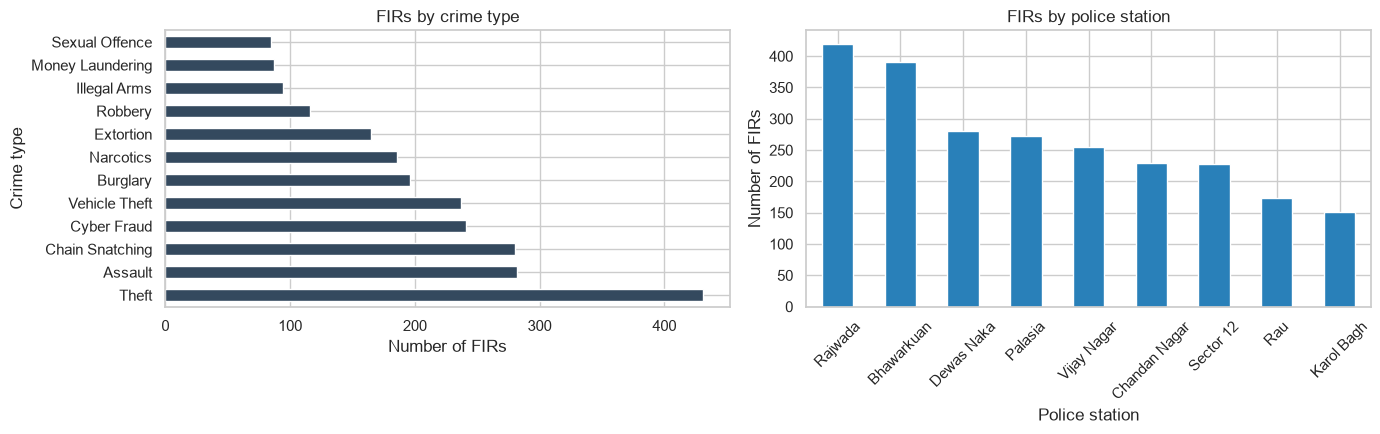

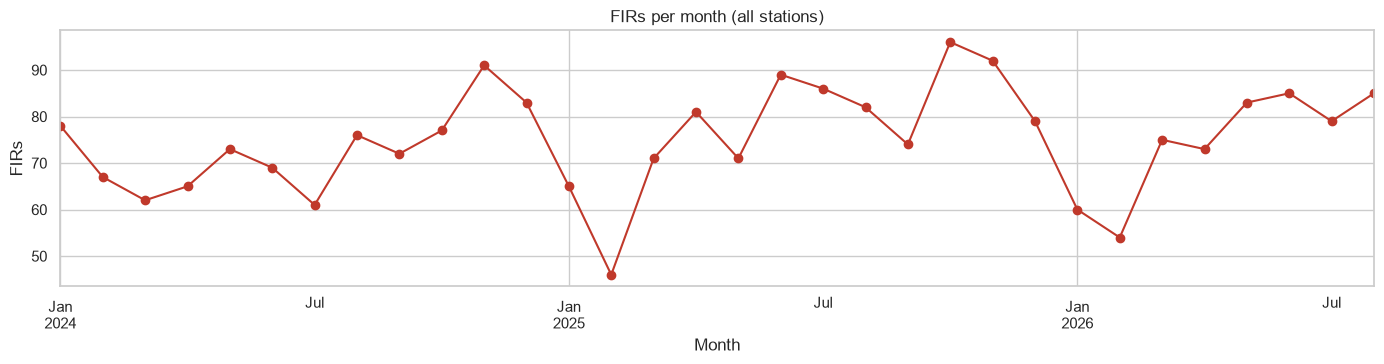

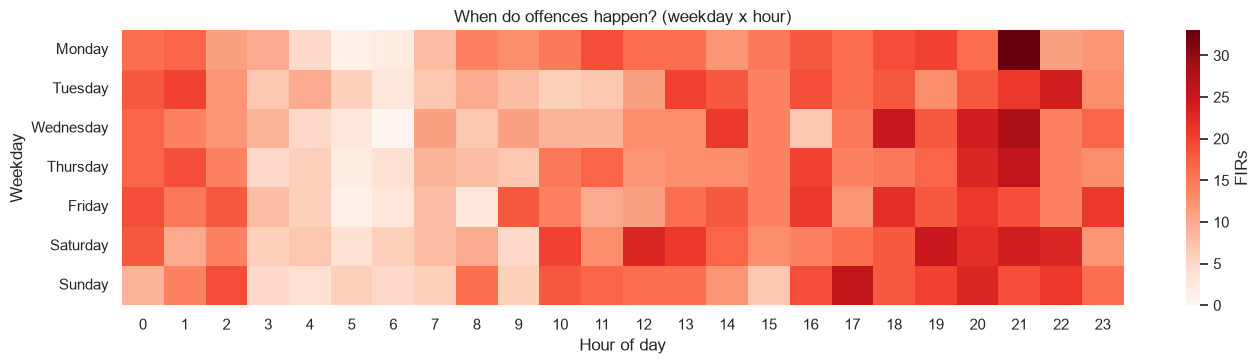

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
cases["crime_type"].value_counts().plot.barh(ax=axes[0], color="#34495e")
axes[0].set_title("FIRs by crime type"); axes[0].set_xlabel("Number of FIRs"); axes[0].set_ylabel("Crime type")
cases["police_station"].value_counts().plot.bar(ax=axes[1], color="#2980b9")
axes[1].set_title("FIRs by police station"); axes[1].set_xlabel("Police station"); axes[1].set_ylabel("Number of FIRs")
axes[1].tick_params(axis="x", rotation=45)
savefig("01_crime_and_station_counts")

monthly = tr.monthly_counts(cases)
ax = monthly["firs"].plot(figsize=(14, 3.8), marker="o", color="#c0392b")
ax.set_title("FIRs per month (all stations)"); ax.set_xlabel("Month"); ax.set_ylabel("FIRs")
savefig("02_monthly_firs")

hw = pd.crosstab(cases["weekday"], cases["hour_of_occurrence"].astype("Int64"))
hw = hw.reindex(["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
plt.figure(figsize=(14, 3.8)); sns.heatmap(hw, cmap="Reds", cbar_kws={"label": "FIRs"})
plt.title("When do offences happen? (weekday x hour)"); plt.xlabel("Hour of day"); plt.ylabel("Weekday")
savefig("03_weekday_hour_heatmap")

### 4.2 Outliers (mid-term stage F)
IQR rule: a value is an outlier when it is below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR.

,column,Q1,Q3,lower,upper,outliers,max
0,property_value_inr,0.0,57300.0,-85950.0,143250.0,209,3881600.0
1,io_caseload,21.0,42.0,-10.5,73.5,0,52.0
2,registration_delay_days,0.0,2.0,-3.0,5.0,189,39.0
3,num_witnesses,1.0,3.0,-2.0,6.0,39,9.0
4,num_accused,1.0,2.0,-0.5,3.5,105,6.0


Raw data-entry errors found before cleaning: 4 num_accused = 99; 5 negative registration delays


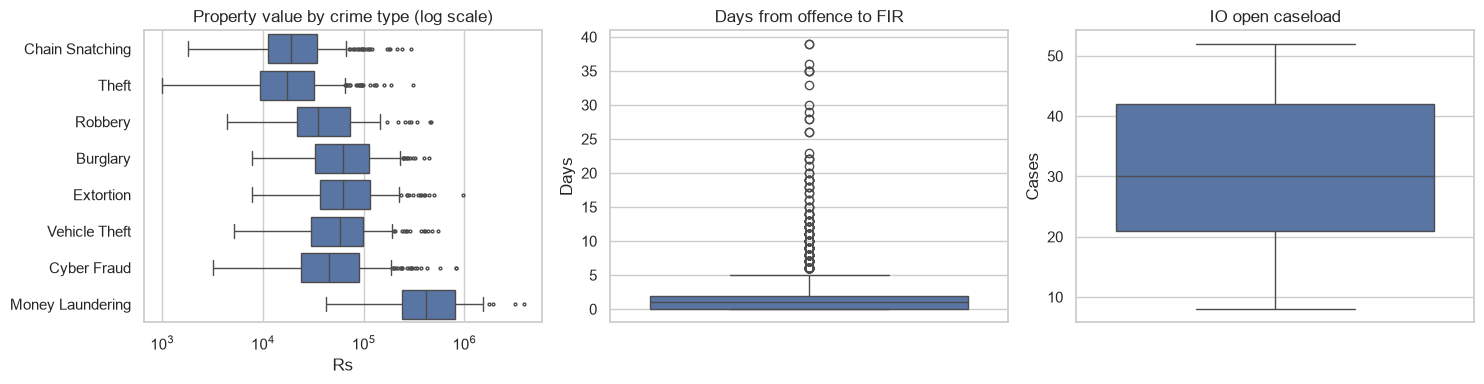

In [15]:
def iqr_report(df, cols):
    rows = []
    for c in cols:
        s = df[c].dropna(); q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        rows.append({"column": c, "Q1": q1, "Q3": q3, "lower": round(lo, 1), "upper": round(hi, 1),
                     "outliers": int(((s < lo) | (s > hi)).sum()), "max": s.max()})
    return pd.DataFrame(rows)

out_cols = ["property_value_inr", "io_caseload", "registration_delay_days", "num_witnesses", "num_accused"]
display(iqr_report(cases, out_cols))
print("Raw data-entry errors found before cleaning:",
      int((raw_cases["num_accused"] > 15).sum()), "num_accused = 99;",
      int((raw_cases["registration_delay_days"] < 0).sum()), "negative registration delays")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(data=cases[cases["property_value_inr"] > 0], x="property_value_inr", y="crime_type", ax=axes[0], fliersize=2)
axes[0].set_xscale("log"); axes[0].set_title("Property value by crime type (log scale)"); axes[0].set_xlabel("Rs"); axes[0].set_ylabel("")
sns.boxplot(data=cases, y="registration_delay_days", ax=axes[1]); axes[1].set_title("Days from offence to FIR"); axes[1].set_ylabel("Days")
sns.boxplot(data=cases, y="io_caseload", ax=axes[2]); axes[2].set_title("IO open caseload"); axes[2].set_ylabel("Cases")
savefig("04_outliers")

**Decisions.**
* `num_accused = 99` and negative `registration_delay_days` are **errors** -> set to missing in cleaning and imputed.
* Large `property_value_inr` values are **genuine** (money-laundering and extortion amounts are large): kept, and a
  log transform reduces their pull on the model (stage E).
* Long `registration_delay_days` are **genuine** (sexual-offence and cyber-fraud complaints are often filed late)
  and carry signal for delay: kept.
* `io_caseload` has no outliers.
Deleting outliers by reflex would remove exactly the serious, complex cases the model must learn about.

### 4.3 Encoding categorical data (mid-term stage C)

| Type | Columns | Scheme |
|---|---|---|
| Binary | `has_cctv`, `has_cdr_evidence`, `has_financial_trail`, `forensic_required`, `repeat_offender_involved` | Yes / No -> 1 / 0 |
| Ordinal | `offence_gravity` | **Low = 0 < Medium = 1 < High = 2** (`OrdinalEncoder` with this explicit order) |
| Nominal | `crime_type`, `police_station`, `season`, `time_of_day` | one-hot (`OneHotEncoder`, unseen values ignored) |

Text and identifier columns (FIR number, names, phones, MO text) are **not** model features: identifiers carry no
general signal and personal data must not drive predictions. MO text is used separately in section 7.

In [16]:
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
X_all, y_all = mp.get_xy(cases)
demo = X_all.groupby("offence_gravity").head(2)
print("Binary (already 0/1):"); display(demo[["has_cctv", "has_cdr_evidence", "has_financial_trail", "forensic_required", "repeat_offender_involved"]])
ord_enc = OrdinalEncoder(categories=[["Low", "Medium", "High"]])
print("Ordinal offence_gravity ->", dict(zip(demo["offence_gravity"], ord_enc.fit_transform(demo[["offence_gravity"]]).ravel())))
oh = OneHotEncoder(handle_unknown="ignore").fit(X_all[["crime_type", "police_station"]].dropna())
print("One-hot columns created for crime_type + police_station:", len(oh.get_feature_names_out()))

Binary (already 0/1):


,has_cctv,has_cdr_evidence,has_financial_trail,forensic_required,repeat_offender_involved
0,1.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.0,0.0,0.0
5,1.0,1.0,0.0,0.0,0.0
6,0.0,1.0,0.0,0.0,0.0
7,0.0,0.0,1.0,1.0,0.0
9,0.0,0.0,1.0,0.0,0.0


Ordinal offence_gravity -> {'Medium': np.float64(1.0), 'Low': np.float64(0.0), 'High': np.float64(2.0)}
One-hot columns created for crime_type + police_station: 21


### 4.4 Binning / discretisation (mid-term stage D)
* `hour_of_occurrence` -> `time_of_day` with **domain-defined** bins that match policing shifts:
  Night 00-06, Morning 06-12, Afternoon 12-18, Evening 18-24. Patrol planning works in shifts, not single hours,
  and the relationship with crime is not linear in the hour number (23 and 0 are neighbours).
* `month` -> `season` (Indian seasons: Winter Dec-Feb, Summer Mar-May, Monsoon Jun-Sep, Post-monsoon Oct-Nov).
* `property_value_inr` -> 4 **equal-frequency** (quantile) bins for reporting, because the values are heavily
  skewed: equal-width bins would put almost every case in the first bin. The model itself uses the log value
  (finer information than 4 bins).

In [17]:
display(cases["time_of_day"].value_counts().rename("FIRs").to_frame())
display(cases["season"].value_counts().rename("FIRs").to_frame())
prop = cases.loc[cases["property_value_inr"] > 0, "property_value_inr"]
q_bins = pd.qcut(prop, q=4, labels=["Q1 low", "Q2", "Q3", "Q4 high"])
w_bins = pd.cut(prop, bins=4)
display(pd.DataFrame({"equal_frequency_bin_counts": q_bins.value_counts().sort_index().values,
                      "equal_width_bin_counts": w_bins.value_counts().sort_index().values},
                     index=["bin 1", "bin 2", "bin 3", "bin 4"]))
print("Equal-frequency bin edges (Rs):", [int(x) for x in pd.qcut(prop, q=4, retbins=True)[1]])

,FIRs
time_of_day,
Evening (18-24),808
Afternoon (12-18),652
Night (00-06),439
Morning (06-12),405


,FIRs
season,
Monsoon,858
Summer,654
Winter,532
Post-monsoon,356


,equal_frequency_bin_counts,equal_width_bin_counts
bin 1,420,1647
bin 2,415,17
bin 3,414,0
bin 4,417,2


Equal-frequency bin edges (Rs): [1000, 17300, 34900, 79575, 3881600]


### 4.5 Scaling and transformation (mid-term stage E)
* `property_value_inr` is heavily right-skewed -> `log1p` (log(1 + x) keeps 0 valid).
* Numeric features -> `StandardScaler` (mean 0, SD 1). Logistic regression and KNN are distance / gradient based and
  need comparable scales; trees do not, but scaling does not hurt them.
* Coordinates for hotspot clustering are converted to kilometres instead of being standard-scaled (section 6).

Skewness before log: 10.36 | after log1p: -0.84


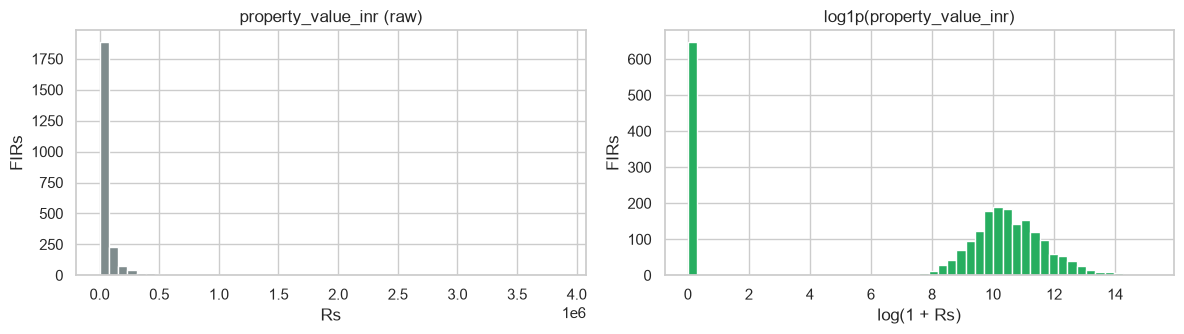

In [18]:
from scipy.stats import skew
pv = cases["property_value_inr"].dropna()
print(f"Skewness before log: {skew(pv):.2f} | after log1p: {skew(np.log1p(pv)):.2f}")
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(pv, bins=50, color="#7f8c8d"); axes[0].set_title("property_value_inr (raw)"); axes[0].set_xlabel("Rs"); axes[0].set_ylabel("FIRs")
axes[1].hist(np.log1p(pv), bins=50, color="#27ae60"); axes[1].set_title("log1p(property_value_inr)"); axes[1].set_xlabel("log(1 + Rs)"); axes[1].set_ylabel("FIRs")
savefig("05_log_transform")

### 4.6 Train/test split, then feature selection and PCA (mid-term stage G)
The split happens **first**. Every selection step below looks only at the training split.

Labelled rows: 2139 -> train 1711, test 428 (stratified, 80/20)
Share of delayed chargesheets: train 34.0%, test 34.1%

Columns in the raw register: 31
Candidate features after removing identifiers / PII / outcome columns: 19


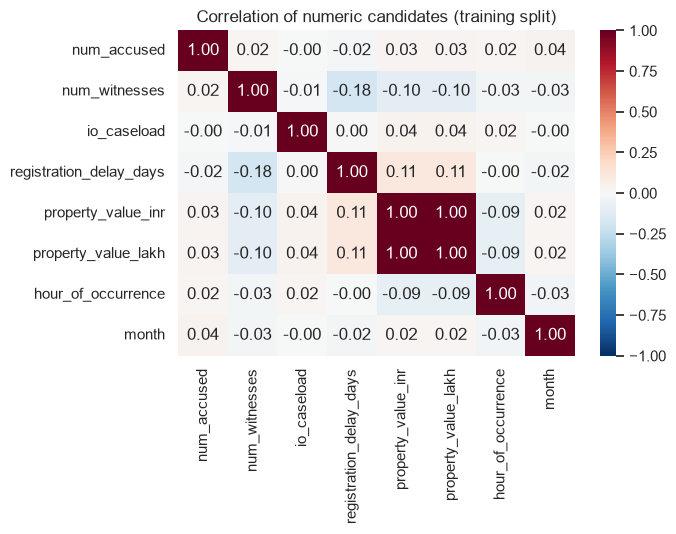

Pairs with |r| > 0.9: [('property_value_inr', 'property_value_lakh', np.float64(1.0))] -> drop property_value_lakh (same information in lakh)
district: 94.1% of training rows are 'Indore' -> near-zero variance, and police_station already encodes it -> dropped
hour_of_occurrence and month -> replaced by the binned time_of_day and season (stage D)

Features kept: 15 -> ['num_accused', 'num_witnesses', 'io_caseload', 'registration_delay_days', 'property_value_inr', 'has_cctv', 'has_cdr_evidence', 'has_financial_trail', 'forensic_required', 'repeat_offender_involved', 'offence_gravity', 'crime_type', 'police_station', 'season', 'time_of_day']


In [19]:
X_train, X_test, y_train, y_test = mp.split(X_all, y_all)
print(f"Labelled rows: {len(X_all)} -> train {len(X_train)}, test {len(X_test)} (stratified, 80/20)")
print(f"Share of delayed chargesheets: train {y_train.mean():.1%}, test {y_test.mean():.1%}")

# 1) Starting point: every column of the raw case register
print(f"\nColumns in the raw register: {raw_cases.shape[1]}")
# 2) Remove identifiers, personal data, outcome columns (leakage) and protected attributes -> candidate features
candidates = MODEL_FEATURES + ["property_value_lakh", "district", "hour_of_occurrence", "month"]
print(f"Candidate features after removing identifiers / PII / outcome columns: {len(candidates)}")

# 3) Correlation filter on the training rows
train_rows = cases.loc[X_train.index]
num_cand = ["num_accused", "num_witnesses", "io_caseload", "registration_delay_days", "property_value_inr",
            "property_value_lakh", "hour_of_occurrence", "month"]
corr = train_rows[num_cand].corr()
plt.figure(figsize=(7, 5.5)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1)
plt.title("Correlation of numeric candidates (training split)"); savefig("06_correlation")
high = [(a, b, round(corr.loc[a, b], 3)) for i, a in enumerate(num_cand) for b in num_cand[i + 1:] if abs(corr.loc[a, b]) > 0.9]
print("Pairs with |r| > 0.9:", high, "-> drop property_value_lakh (same information in lakh)")

# 4) Variance threshold: district is almost constant
share = train_rows["district"].value_counts(normalize=True)
print(f"district: {share.iloc[0]:.1%} of training rows are '{share.index[0]}' -> near-zero variance, and police_station already encodes it -> dropped")
print("hour_of_occurrence and month -> replaced by the binned time_of_day and season (stage D)")
print(f"\nFeatures kept: {len(MODEL_FEATURES)} -> {MODEL_FEATURES}")

After encoding: 40 numeric columns (from 15 features)


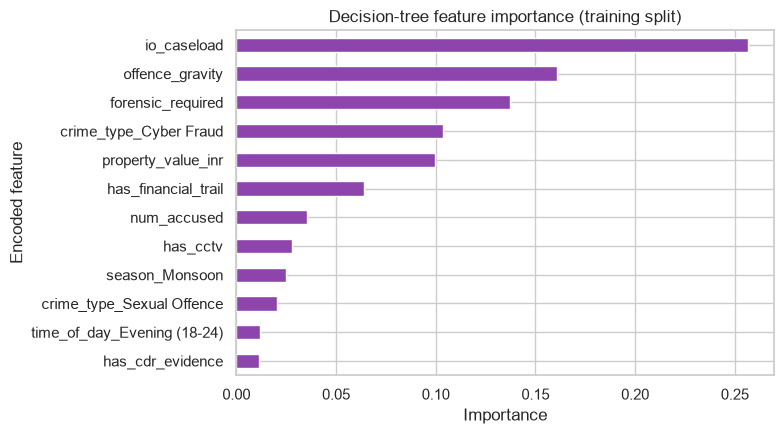

Encoded columns with zero tree importance: 22


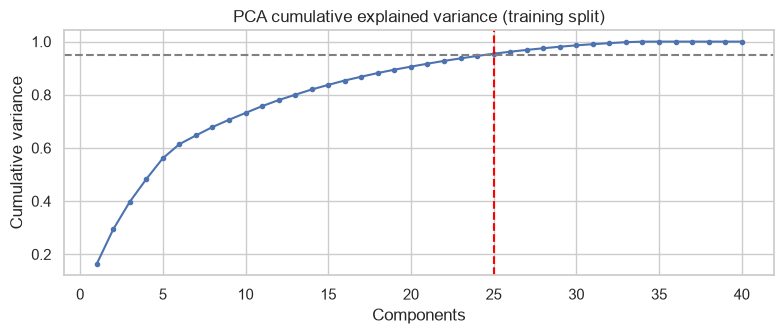

PCA: 25 of 40 components keep 95% of the variance
Logistic regression CV F1 - all encoded features: 0.616 | 25 PCA components: 0.620


In [20]:
from sklearn.decomposition import PCA
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

imp = mp.GroupMedianImputer().fit(X_train)
prep = mp.build_preprocessor().fit(imp.transform(X_train))
Xt_train = prep.transform(imp.transform(X_train))
Xt_train = Xt_train.toarray() if hasattr(Xt_train, "toarray") else Xt_train
enc_names = prep.get_feature_names_out()
print(f"After encoding: {Xt_train.shape[1]} numeric columns (from {len(MODEL_FEATURES)} features)")

# Model-based importance (decision tree on the training split)
tree = DecisionTreeClassifier(max_depth=6, min_samples_leaf=20, random_state=RANDOM_STATE).fit(Xt_train, y_train)
imp_df = pd.Series(tree.feature_importances_, index=enc_names).sort_values(ascending=False)
ax = imp_df.head(12).iloc[::-1].plot.barh(figsize=(8, 4.5), color="#8e44ad")
ax.set_title("Decision-tree feature importance (training split)"); ax.set_xlabel("Importance"); ax.set_ylabel("Encoded feature")
savefig("07_tree_importance")
print("Encoded columns with zero tree importance:", int((imp_df == 0).sum()))

# PCA: how many components keep 95% of the variance?
pca = PCA().fit(Xt_train)
cum = np.cumsum(pca.explained_variance_ratio_)
k95 = int(np.argmax(cum >= 0.95) + 1)
plt.figure(figsize=(8, 3.5)); plt.plot(range(1, len(cum) + 1), cum, marker=".")
plt.axhline(0.95, ls="--", c="grey"); plt.axvline(k95, ls="--", c="red")
plt.title("PCA cumulative explained variance (training split)"); plt.xlabel("Components"); plt.ylabel("Cumulative variance")
savefig("08_pca")
print(f"PCA: {k95} of {Xt_train.shape[1]} components keep 95% of the variance")

lr = LogisticRegression(max_iter=3000, class_weight="balanced")
f1_full = cross_val_score(lr, Xt_train, y_train, cv=5, scoring="f1").mean()
f1_pca = cross_val_score(lr, PCA(n_components=k95).fit_transform(Xt_train), y_train, cv=5, scoring="f1").mean()
print(f"Logistic regression CV F1 - all encoded features: {f1_full:.3f} | {k95} PCA components: {f1_pca:.3f}")

**Decision (stage G).** Raw register 31 columns -> 15 model features (identifiers, personal data, outcome columns,
the redundant `property_value_lakh`, the near-constant `district` and the raw hour / month removed) -> encoded
columns after one-hot, with a `VarianceThreshold` in the pipeline that drops any constant column. PCA was evaluated:
it still needs most of the components to keep 95% of the variance and gives about the same cross-validated F1 (printed
above), so it brings no real gain, while its components (mixtures of all features) cannot be explained to a police
supervisor. So the final model uses the selected features **without PCA**.

## 5. Crime trend analysis and forecasting
### 5.1 Rise or fall by crime type and by area
Year-on-year: the last 6 months compared with the **same 6 months a year earlier**, which removes seasonality.
A change of at least +/-20% with enough FIRs is reported as Rise / Fall.

In [21]:
city_trends = tr.trend_changes(cases, "crime_type")
area_trends = tr.trend_changes(cases, ["police_station", "crime_type"], min_count=8)
print("Window:", city_trends.attrs["window"])
display(city_trends)
print("Biggest rises by area:"); display(area_trends[area_trends["direction"] == "Rise"].head(10))

Window: 2026-03..2026-08 vs 2025-03..2025-08


,crime_type,recent,year_before,change_pct,direction
0,Cyber Fraud,89,38,134.2,Rise
1,Extortion,40,28,42.9,Rise
2,Narcotics,43,41,4.9,Stable
3,Theft,79,77,2.6,Stable
4,Illegal Arms,23,23,0.0,Stable
5,Burglary,35,36,-2.8,Stable
6,Vehicle Theft,39,41,-4.9,Stable
7,Robbery,21,23,-8.7,Stable
8,Assault,55,68,-19.1,Stable
9,Sexual Offence,18,24,-25.0,Fall


Biggest rises by area:


,police_station,crime_type,recent,year_before,change_pct,direction
0,Rajwada,Cyber Fraud,13,1,1200.0,Rise
1,Bhawarkuan,Extortion,17,4,325.0,Rise
2,Vijay Nagar,Burglary,8,2,300.0,Rise
3,Karol Bagh,Cyber Fraud,7,2,250.0,Rise
4,Rau,Theft,7,3,133.3,Rise
5,Rajwada,Extortion,11,5,120.0,Rise
6,Bhawarkuan,Cyber Fraud,19,9,111.1,Rise
7,Vijay Nagar,Cyber Fraud,20,10,100.0,Rise
8,Dewas Naka,Vehicle Theft,11,6,83.3,Rise
9,Sector 12,Cyber Fraud,7,4,75.0,Rise


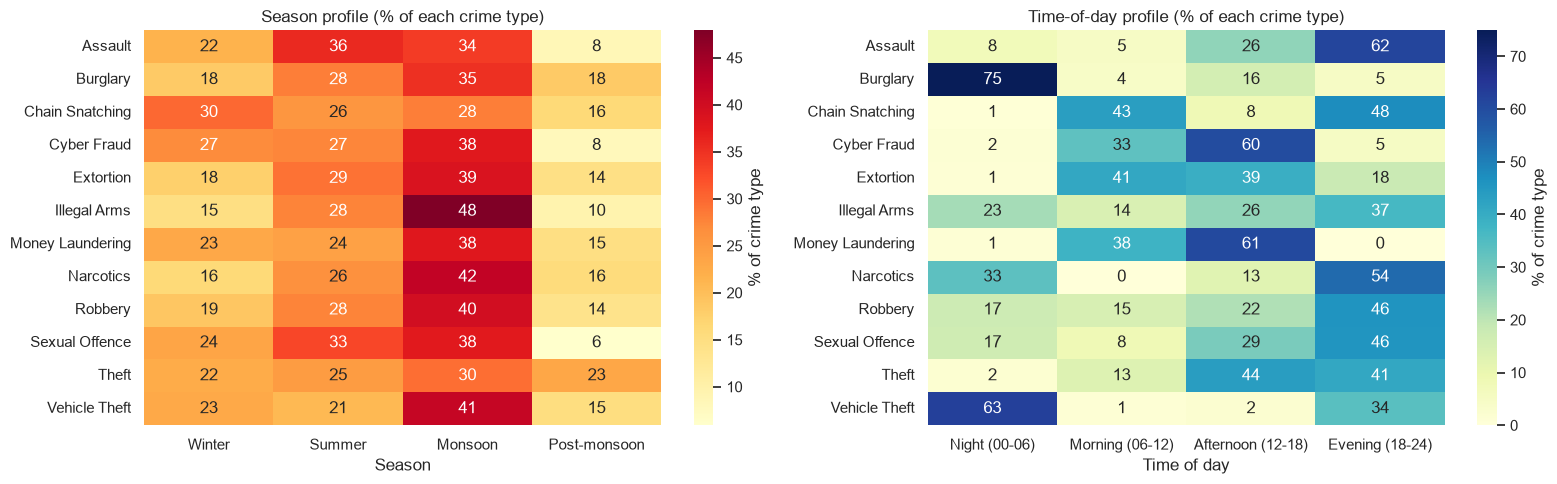

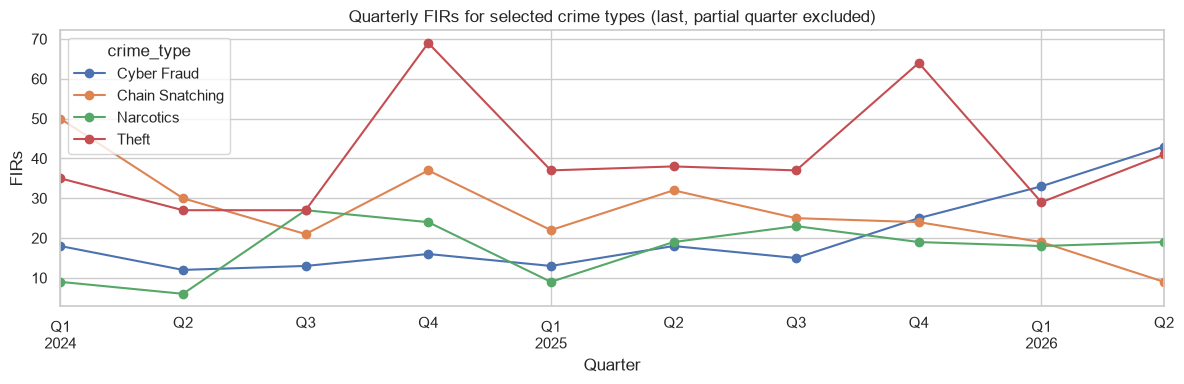

,police_station,peak_time_of_day,peak_share_%,peak_weekday,peak_hour
0,Bhawarkuan,Evening (18-24),37.5,Saturday,21
1,Chandan Nagar,Evening (18-24),36.8,Friday,21
2,Dewas Naka,Evening (18-24),39.9,Wednesday,22
3,Karol Bagh,Evening (18-24),44.2,Friday,19
4,Palasia,Evening (18-24),32.7,Friday,21
5,Rajwada,Evening (18-24),34.1,Saturday,19
6,Rau,Afternoon (12-18),36.7,Tuesday,10
7,Sector 12,Evening (18-24),32.4,Sunday,17
8,Vijay Nagar,Evening (18-24),34.2,Saturday,13


In [22]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(tr.season_profile(cases), annot=True, fmt=".0f", cmap="YlOrRd", ax=axes[0], cbar_kws={"label": "% of crime type"})
axes[0].set_title("Season profile (% of each crime type)"); axes[0].set_xlabel("Season"); axes[0].set_ylabel("")
sns.heatmap(tr.time_of_day_profile(cases), annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[1], cbar_kws={"label": "% of crime type"})
axes[1].set_title("Time-of-day profile (% of each crime type)"); axes[1].set_xlabel("Time of day"); axes[1].set_ylabel("")
savefig("09_season_time_profiles")

top_types = ["Cyber Fraud", "Chain Snatching", "Narcotics", "Theft"]
q = cases.assign(q=cases["date_occurred"].dt.to_period("Q").dt.start_time).pivot_table(index="q", columns="crime_type", values="fir_no", aggfunc="count")[top_types]
ax = q.iloc[:-1].plot(figsize=(12, 4), marker="o")
ax.set_title("Quarterly FIRs for selected crime types (last, partial quarter excluded)"); ax.set_xlabel("Quarter"); ax.set_ylabel("FIRs")
savefig("10_quarterly_trends")
peaks = tr.peak_times(cases); display(peaks)

### 5.2 Forecast of FIRs per police station for the next 4 weeks
Three models are compared with a rolling-origin backtest over the last 12 weeks (mean absolute error, FIRs/week):
* **naive mean of the last 4 weeks** (baseline every model must beat);
* **Holt-Winters exponential smoothing** with a damped trend (`statsmodels`), good for short, noisy count series;
* **linear regression** on a time index plus yearly sine / cosine terms (captures festival-season peaks).

The best model per station produces the forecast. Prophet was not used: it adds a heavy dependency and, with about
2 FIRs per station per week, simple models are as accurate and easier to explain.

model,holt_winters,linear_fourier,naive_mean4,best
police_station,,,,
Bhawarkuan,1.93,2.02,1.83,naive_mean4
Chandan Nagar,0.81,0.96,0.96,holt_winters
Dewas Naka,1.42,1.42,1.54,holt_winters
Karol Bagh,0.94,1.08,1.08,holt_winters
Palasia,1.20,1.31,1.25,holt_winters
Rajwada,0.93,0.92,0.96,linear_fourier
Rau,0.78,0.83,0.88,holt_winters
Sector 12,1.03,0.98,1.08,linear_fourier
Vijay Nagar,1.89,1.85,1.96,linear_fourier


,police_station,forecast_next_weeks,forecast_per_week,recent_12wk_avg,best_model,backtest_mae,peak_time_of_day,peak_weekday,forecast_start,risk_rank
0,Bhawarkuan,17.0,4.25,3.67,naive_mean4,1.83,Evening (18-24),Saturday,2026-08-31,1
1,Rajwada,13.7,3.43,2.75,linear_fourier,0.92,Evening (18-24),Saturday,2026-08-31,2
2,Dewas Naka,8.6,2.16,2.25,holt_winters,1.42,Evening (18-24),Wednesday,2026-08-31,3
3,Palasia,8.3,2.09,2.17,holt_winters,1.20,Evening (18-24),Friday,2026-08-31,4
4,Vijay Nagar,7.7,1.92,2.17,linear_fourier,1.85,Evening (18-24),Saturday,2026-08-31,5
5,Chandan Nagar,6.8,1.69,1.92,holt_winters,0.81,Evening (18-24),Friday,2026-08-31,6
6,Rau,5.3,1.32,1.17,holt_winters,0.78,Afternoon (12-18),Tuesday,2026-08-31,7
7,Sector 12,5.1,1.27,1.42,linear_fourier,0.98,Evening (18-24),Sunday,2026-08-31,8
8,Karol Bagh,4.2,1.06,1.25,holt_winters,0.94,Evening (18-24),Friday,2026-08-31,9


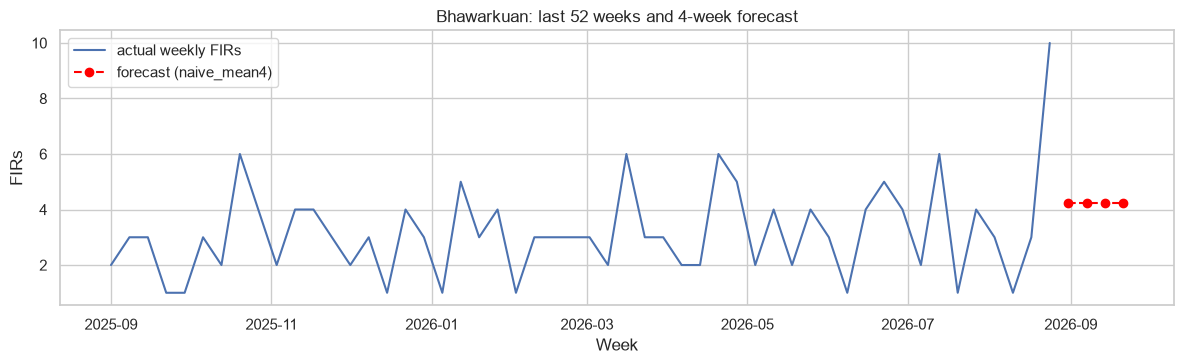

In [23]:
forecast, backtest = tr.forecast_hotspots(cases, horizon=4, holdout=12)
display(backtest.pivot(index="police_station", columns="model", values="mae").round(2).assign(
    best=lambda d: d.idxmin(axis=1)))
display(forecast)

panel = tr.weekly_panel(cases)
top = forecast.iloc[0]["police_station"]
y = panel[top]
fut = pd.date_range(y.index[-1] + pd.Timedelta(weeks=1), periods=4, freq="W-MON")
pred = tr._fit_predict(forecast.iloc[0]["best_model"], y, 4)
plt.figure(figsize=(12, 3.8)); plt.plot(y.index[-52:], y.iloc[-52:], label="actual weekly FIRs")
plt.plot(fut, pred, "o--", c="red", label=f"forecast ({forecast.iloc[0]['best_model']})")
plt.title(f"{top}: last 52 weeks and 4-week forecast"); plt.xlabel("Week"); plt.ylabel("FIRs"); plt.legend()
savefig("11_forecast_top_station")

## 6. Hotspot mapping (interactive folium map)
### 6.1 Patrol zones with K-Means and the elbow method
Latitude / longitude are converted to kilometres so that distances are real distances. K-Means is run for
k = 2..15 and the elbow (the point of the inertia curve farthest from the straight line between its ends) picks k.

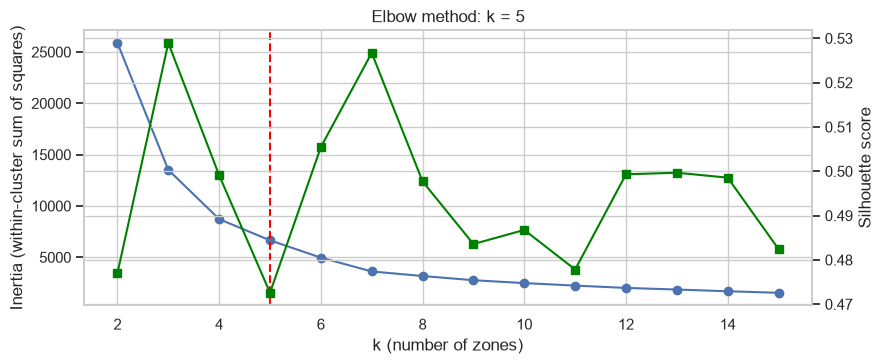

,zone,firs,lat,lon,top_station,top_crime,top_time,last_90d,radius_km,share_%,density_per_km2
0,3,541,22.758645,75.897997,Dewas Naka,Theft,Evening (18-24),56,1.73,24.1,57.5
1,1,660,22.721595,75.868099,Rajwada,Theft,Evening (18-24),64,2.12,29.3,46.7
2,2,180,22.633565,75.810951,Rau,Money Laundering,Afternoon (12-18),16,1.43,8.0,28.0
3,4,509,22.691953,75.857497,Bhawarkuan,Theft,Evening (18-24),57,2.44,22.6,27.2
4,0,359,22.711292,75.822769,Chandan Nagar,Theft,Evening (18-24),37,2.23,16.0,23.0


In [24]:
zone_inc, zones, elbow = hs.find_zones(cases)
k_best = hs.knee_point(elbow)
fig, ax1 = plt.subplots(figsize=(9, 3.8))
ax1.plot(elbow["k"], elbow["inertia"], marker="o"); ax1.axvline(k_best, ls="--", c="red")
ax1.set_xlabel("k (number of zones)"); ax1.set_ylabel("Inertia (within-cluster sum of squares)")
ax2 = ax1.twinx(); ax2.plot(elbow["k"], elbow["silhouette"], marker="s", c="green"); ax2.set_ylabel("Silhouette score")
ax1.set_title(f"Elbow method: k = {k_best}"); savefig("12_elbow_kmeans")
display(zones)

### 6.2 Dense hotspots with DBSCAN
DBSCAN groups incidents that have at least 25 neighbours within 250 m and leaves scattered incidents as noise.
It does not need the number of hotspots in advance and finds hotspots of any shape, which suits picket placement.

In [25]:
hot_inc, hotspots = hs.find_dense_hotspots(cases, eps_km=0.25, min_samples=25)
print(f"Hotspots found: {len(hotspots)}; incidents inside hotspots: {(hot_inc['hotspot'] >= 0).mean():.0%}")
display(hotspots)
display(hs.station_concentration(cases))

Hotspots found: 15; incidents inside hotspots: 52%


,hotspot,firs,lat,lon,top_station,top_crime,top_time,last_90d,radius_km,share_%,density_per_km2,is_hotspot
0,0,154,22.713135,75.860388,Rajwada,Theft,Afternoon (12-18),17,0.44,13.2,253.2,True
1,7,132,22.725826,75.850930,Rajwada,Theft,Evening (18-24),8,0.43,11.3,227.2,True
2,3,124,22.691416,75.869913,Bhawarkuan,Theft,Evening (18-24),15,0.44,10.6,203.9,True
3,1,128,22.702098,75.859761,Bhawarkuan,Theft,Evening (18-24),13,0.45,10.9,201.2,True
4,5,46,22.724683,75.815522,Chandan Nagar,Chain Snatching,Evening (18-24),5,0.28,3.9,186.8,True
5,14,49,22.712151,75.822514,Chandan Nagar,Assault,Afternoon (12-18),9,0.29,4.2,185.5,True
6,9,79,22.762128,75.891386,Vijay Nagar,Theft,Evening (18-24),11,0.39,6.8,165.3,True
7,11,67,22.759097,75.907495,Dewas Naka,Theft,Evening (18-24),5,0.36,5.7,164.6,True
8,6,78,22.769904,75.896426,Dewas Naka,Narcotics,Evening (18-24),10,0.39,6.7,163.2,True
9,8,45,22.734426,75.880442,Palasia,Chain Snatching,Evening (18-24),6,0.30,3.8,159.2,True


,police_station,district,firs,share_%
0,Rajwada,Indore,420,17.5
1,Bhawarkuan,Indore,390,16.2
2,Dewas Naka,Indore,280,11.7
3,Palasia,Indore,273,11.4
4,Vijay Nagar,Indore,255,10.6
5,Chandan Nagar,Indore,230,9.6
6,Sector 12,Indore,227,9.5
7,Rau,Indore,174,7.2
8,Karol Bagh,Delhi,151,6.3


In [26]:
fmap = hs.build_map(hot_inc, hotspots, zones=zones, forecast=forecast, out_html=str(REPORT_DIR / "hotspot_map.html"))
print("Saved reports/hotspot_map.html")
fmap

Saved reports/hotspot_map.html


## 7. Modus operandi similarity matching (NLP)
1. Normalise text (section 3.4) and fit TF-IDF on word 1-2 grams + character 3-5 grams.
2. Cosine similarity between FIRs of the same crime type; pairs with similarity >= 0.7 **and within 45 days** are linked
   (offenders work in sprees, while a common MO recurs all year).
3. A **series** is a tight group of linked FIRs (density >= 0.65: almost every FIR matches every other).
4. Check against documented records: how often do FIRs in a series name a common accused, compared with random pairs?
5. The same steps are repeated with multilingual sentence embeddings (`paraphrase-multilingual-MiniLM-L12-v2`, which
   reads Hindi directly) blended with TF-IDF. **The method with the higher records-check score is kept.** If the
   model cannot be downloaded, TF-IDF is used.

In [27]:
def run_mo(matcher):
    pairs = mo.find_similar_pairs(anon, matcher, threshold=0.7, max_days=45)
    series = mo.group_series(pairs, anon)
    return pairs, series, mo.evaluate_against_records(mo.series_pairs(series), anon)

matcher = mo.MOMatcher(use_embeddings=False).fit(anon["modus_operandi"])
pairs, series, eval_series = run_mo(matcher)
rows = [{"method": "TF-IDF + Hindi/Hinglish glossary", "linked_pairs": len(pairs), "series": len(series), **eval_series}]
if USE_EMBEDDINGS:
    emb_matcher = mo.MOMatcher(use_embeddings=True).fit(anon["modus_operandi"])
    emb_result = run_mo(emb_matcher)
    print("Embedding status:", emb_matcher.embedding_status)
    if emb_matcher.use_embeddings:
        rows.append({"method": "TF-IDF + multilingual embeddings", "linked_pairs": len(emb_result[0]),
                     "series": len(emb_result[1]), **emb_result[2]})
        if emb_result[2]["matched_share_common_accused"] > eval_series["matched_share_common_accused"]:
            matcher, (pairs, series, eval_series) = emb_matcher, emb_result
mo_comparison = pd.DataFrame(rows).drop(columns=["matched_pairs"])
display(mo_comparison)
print("Kept:", "embeddings" if matcher.use_embeddings else "TF-IDF + glossary")
print(f"FIRs in a reported series name a common accused {eval_series['matched_share_common_accused']:.0%} of the time, "
      f"versus {eval_series['random_share_common_accused']:.1%} for random FIR pairs of the same crime type.")
display(pairs.head(8))
display(series.drop(columns=["fir_numbers"]).head(12))

Embedding status: using paraphrase-multilingual-MiniLM-L12-v2


,method,linked_pairs,series,matched_share_common_accused,random_share_common_accused
0,TF-IDF + Hindi/Hinglish glossary,964,14,0.804,0.013
1,TF-IDF + multilingual embeddings,1506,18,0.552,0.013


Kept: TF-IDF + glossary
FIRs in a reported series name a common accused 80% of the time, versus 1.3% for random FIR pairs of the same crime type.


,fir_a,fir_b,crime_type,similarity,station_a,station_b,days_apart
0,BHK/0100/2026,RAU/0038/2026,Cyber Fraud,1.0,Bhawarkuan,Rau,10
1,VJN/0071/2024,VJN/0001/2025,Theft,1.0,Vijay Nagar,Vijay Nagar,35
2,RAU/0034/2024,RAU/0043/2024,Assault,1.0,Rau,Rau,35
3,BHK/0040/2025,BHK/0041/2025,Theft,1.0,Bhawarkuan,Bhawarkuan,1
4,RJW/0071/2025,RJW/0082/2025,Sexual Offence,1.0,Rajwada,Rajwada,28
5,VJN/0047/2026,BHK/0099/2026,Cyber Fraud,1.0,Vijay Nagar,Bhawarkuan,41
6,CHN/0058/2025,CHN/0065/2025,Assault,1.0,Chandan Nagar,Chandan Nagar,26
7,RJW/0112/2025,RJW/0113/2025,Chain Snatching,1.0,Rajwada,Rajwada,3


,series_size,density,mean_similarity,crime_type,stations,n_stations,first_date,last_date,pending_in_series,example_mo,cohesion
0,8,0.82,0.784,Narcotics,"Dewas Naka, Karol Bagh",2,2024-08-26,2024-10-26,0,Highway dhaba par Delhi number ki gaadi DL1CAB1234 se maal ka packet diya gaya. Padosi...,6.56
1,5,1.00,0.807,Extortion,"Bhawarkuan, Rajwada, Sector 12",3,2026-05-02,2026-05-11,0,Shopkeeper near Bhawarkuan threatened by men in vehicle MP09AB1234; they demanded week...,5.00
2,5,1.00,0.888,Extortion,"Bhawarkuan, Rajwada",2,2026-04-28,2026-06-01,1,Protection money demanded from shop owner near Bhawarkuan by two men arriving in vehic...,5.00
3,5,1.00,0.811,Narcotics,"Dewas Naka, Karol Bagh",2,2024-08-26,2024-10-07,0,Package handed over at highway dhaba near Dewas Naka; contraband arrived in Delhi regi...,5.00
4,5,1.00,0.820,Illegal Arms,"Palasia, Sector 12",2,2025-08-01,2025-09-06,0,Country-made pistols supplied from Palasia; buyer contacted through a taxi driver acti...,5.00
5,5,1.00,0.833,Extortion,Sector 12,1,2025-09-07,2025-10-04,0,Shopkeeper near Sector 12 threatened by men in vehicle MP09AB1234; they demanded weekl...,5.00
6,6,0.73,0.763,Chain Snatching,"Chandan Nagar, Palasia, Rajwada, Vijay Nagar",4,2025-08-16,2025-10-14,0,Two youths on a black motorcycle without number plate snatched gold chain from a woman...,4.38
7,4,1.00,0.801,Narcotics,"Dewas Naka, Karol Bagh",2,2025-06-27,2025-07-18,0,Contraband package exchanged at a dhaba on the highway near Dewas Naka; Delhi-register...,4.00
8,4,1.00,0.860,Extortion,Sector 12,1,2024-04-13,2024-05-08,0,Protection money demanded from shop owner near Sector 12 by two men arriving in vehicl...,4.00
9,5,0.70,0.828,Cyber Fraud,"Palasia, Rajwada, Rau",3,2024-07-25,2024-09-29,0,"सुबह में बैंक अधिकारी बनकर फोन किया और ओटीपी लेकर खाते से Rs 75,000 निकाल लिए। शिकायतक...",3.50


### 7.1 MO clusters (K-Means on LSA text vectors)
TruncatedSVD (PCA for sparse text matrices, also called LSA) reduces the TF-IDF matrix to 50 dimensions, then
K-Means with the elbow method groups FIRs into MO families. This is the course K-Means method applied to text.

In [28]:
mo_labels, mo_curve, lsa_var = mo.cluster_mo(anon["modus_operandi"], matcher)
anon["mo_cluster"] = mo_labels
print(f"LSA keeps {lsa_var:.0%} of TF-IDF variance in 50 dimensions; elbow k = {anon['mo_cluster'].nunique()}")
fam = (anon.groupby("mo_cluster").agg(firs=("fir_no", "count"), main_crime=("crime_type", lambda s: s.value_counts().index[0]),
                                       purity=("crime_type", lambda s: round(s.value_counts(normalize=True).iloc[0], 2)),
                                       example=("modus_operandi", "first")).sort_values("firs", ascending=False))
display(fam)

LSA keeps 62% of TF-IDF variance in 50 dimensions; elbow k = 10


,firs,main_crime,purity,example
mo_cluster,,,,
9,590,Extortion,0.21,Blade and live cartridges recovered from accused during vehicle checking near Chandan ...
0,357,Theft,0.39,Chandan Nagar पार्क के पास रात में अज्ञात व्यक्ति ने शिकायतकर्ता का लैपटॉप चोरी कर लिय...
2,280,Chain Snatching,1.00,A youth on a red motorcycle snatched gold chain from a woman near Palasia vegetable ma...
1,236,Theft,0.62,Unknown person stole wallet from complainant's bag in crowded Bhawarkuan market in the...
7,223,Narcotics,0.36,Chopper dikha kar two logon ne Bhawarkuan railway crossing ke raste mein gold ring loo...
3,157,Cyber Fraud,0.97,"Loan app agent ban kar phone call bheja, OTP lekar khaate se Rs 1.2 lakh nikaal liye. ..."
4,149,Assault,1.00,Quarrel over parking near Bhawarkuan vegetable market turned violent; complainant beat...
8,145,Theft,1.00,"Rajwada mein shop ke counter se silver anklet chori, on a holiday ek ladka dikh raha t..."
5,133,Assault,1.00,Vijay Nagar पार्क के पास रात में विवाद के बाद आरोपियों ने शिकायतकर्ता के साथ मारपीट की...


## 8. Criminal network / link analysis (networkx)
Edges come from: phone calls (CDR), money transfers, people named together in FIR / intelligence documents,
social-media tips, and co-accused in the FIR register. Measures:
* **betweenness centrality**: how often a person sits on the shortest path between others (a broker / kingpin);
* **PageRank**: importance from being linked to important people;
* **communities** (greedy modularity): sub-groups;
* **Adamic-Adar link prediction**: likely but unrecorded links (to verify, never to accuse);
* **money loops**: funds that return to the sender (layering).

Network: 10 nodes, 25 edges


,node,type,degree,weighted_degree,betweenness,pagerank,community,link_types,kingpin_score
0,P-3ce0003a,person,9,102.21,0.359,0.188,0,"call, co-accused, co-mention, money",1.000
1,P-207f6df6,person,7,48.92,0.081,0.094,1,"call, co-accused, co-mention, money, tip",0.800
2,P-36508347,person,6,91.50,0.046,0.163,1,"call, co-accused, co-mention, tip",0.800
3,P-75646758,person,5,48.89,0.007,0.099,0,"call, co-accused, co-mention, money, tip",0.675
4,P-14639809,person,5,43.00,0.056,0.085,1,"call, co-accused, co-mention",0.600
5,P-fa16c517,person,3,48.00,0.000,0.089,1,"call, co-accused, co-mention",0.425
6,P-7a0e69c0,person,4,43.06,0.000,0.087,0,"call, co-accused, co-mention, money, tip",0.375
7,Chatterjee Traders,organisation,5,14.67,0.007,0.039,0,"co-mention, money, tip",0.325
8,P-f7c03091,person,3,29.09,0.000,0.080,2,"call, co-accused, co-mention, money",0.275
9,P-3ce15d11,person,3,26.00,0.000,0.074,2,"call, co-accused, co-mention, money",0.225


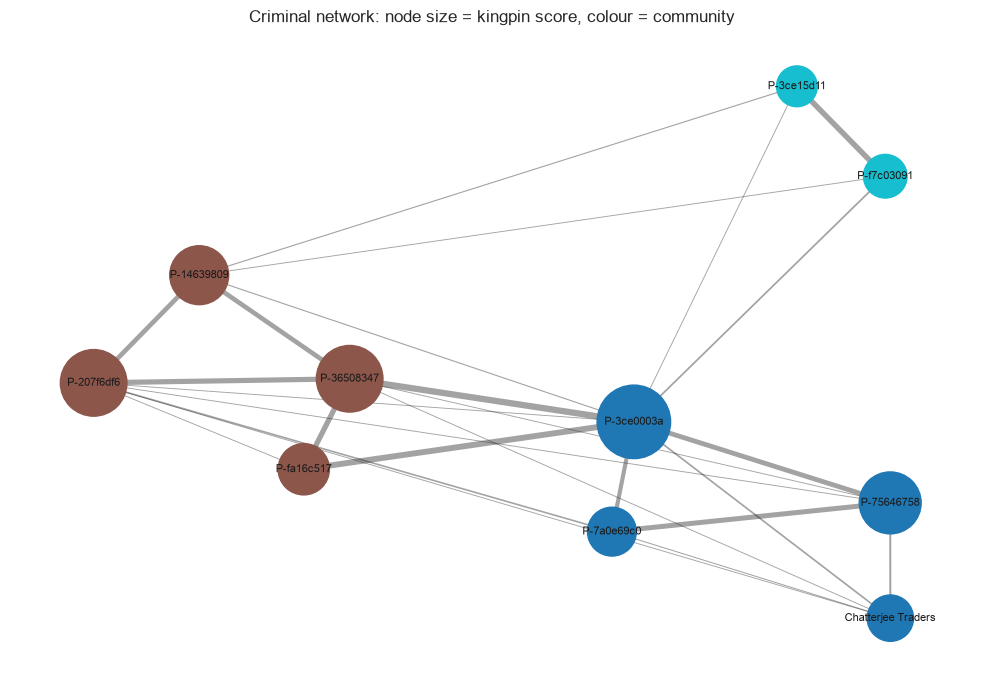

In [29]:
G, extracted = na.build_intel_graph(src, registry)
G = na.add_case_edges(G, cases, registry, only_known=True)
print(f"Network: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges")
centrality = na.centrality_table(G)
display(centrality.assign(node=centrality["node"].map(lambda n: n if G.nodes[n].get("type") == "organisation" else label(n))))
label_map = {n: (n if G.nodes[n].get("type") == "organisation" else label(n)) for n in G.nodes}
fig_net = na.plot_network(G, centrality, label_map=label_map, out_html=str(REPORT_DIR / "network.html"),
                          title="Criminal network (size = kingpin score, colour = community)")

import networkx as nx
pos = nx.spring_layout(G, seed=RANDOM_STATE, weight="weight", k=0.9)
cmap = centrality.set_index("node")
plt.figure(figsize=(10, 7))
nx.draw_networkx_edges(G, pos, alpha=0.4, width=[0.5 + 0.15 * d["weight"] for *_, d in G.edges(data=True)])
nx.draw_networkx_nodes(G, pos, node_size=[300 + 2500 * cmap.loc[n, "kingpin_score"] for n in G],
                       node_color=[cmap.loc[n, "community"] for n in G], cmap="tab10")
nx.draw_networkx_labels(G, pos, labels=label_map, font_size=8)
plt.title("Criminal network: node size = kingpin score, colour = community"); plt.axis("off")
savefig("13_network")

In [30]:
hidden = na.suggest_hidden_links(G)
cycles = na.money_cycles(src["financial"])
bursts = na.burst_calls(src["cdr"])
print("Possible unrecorded links (Adamic-Adar):")
display(hidden.assign(person_a=hidden["person_a"].map(label), person_b=hidden["person_b"].map(label),
                      common_contacts=hidden["common_contacts"].map(lambda s: ", ".join(label_map.get(x, x) for x in s.split(", ")))).head(6))
print("Money loops:"); display(cycles.assign(holders=cycles["holders"].map(lambda s: " -> ".join(label_map.get(x, x) for x in s.split(" -> ")))))
print("Bursts of very short calls:"); display(bursts.assign(caller=bursts["caller"].map(lambda n: label(registry.resolve(n) or n)), callee=bursts["callee"].map(label)))

Possible unrecorded links (Adamic-Adar):


,person_a,person_b,adamic_adar,common_contacts
0,P-36508347,P-7a0e69c0,2.212,"Chatterjee Traders, P-207f6df6, P-75646758, P-3ce0003a"
1,P-14639809,P-fa16c517,1.527,"P-207f6df6, P-36508347, P-3ce0003a"
2,P-75646758,P-fa16c517,1.527,"P-207f6df6, P-36508347, P-3ce0003a"
3,P-14639809,P-75646758,1.527,"P-207f6df6, P-36508347, P-3ce0003a"
4,P-36508347,P-f7c03091,1.076,"P-14639809, P-3ce0003a"
5,P-207f6df6,P-f7c03091,1.076,"P-14639809, P-3ce0003a"


Money loops:


,accounts,holders,amounts,retained_%,first_leg,last_leg
0,ACC1002 -> ACC1004 -> ACC1001 -> ACC1002,P-75646758 -> Chatterjee Traders -> P-3ce0003a -> P-75646758,"480,000, 460,000, 500,000",92.0,2026-08-05T10:00:00,2026-08-07T09:15:00


Bursts of very short calls:


,caller,callee,short_calls,avg_seconds,from,to,tower
0,P-3ce0003a,P-fa16c517,4,8.5,2026-08-09 07:01:00,2026-08-09 18:32:00,Chandan Nagar Indore


### 8.1 Repeat offenders and cross-jurisdiction links (documented records only)

In [31]:
repeat = na.repeat_offenders(cases, hist, registry)
print(f"People named in 2 or more FIRs: {len(repeat)}")
display(repeat.head(12).assign(name=lambda d: d["name"].map(label)))
cross = repeat[(repeat["districts"] > 1)]
print(f"Accused with FIRs in more than one district: {len(cross)}")
display(cross.head(8)[["name", "fir_count", "station_list", "districts"]].assign(name=lambda d: d["name"].map(label)))

People named in 2 or more FIRs: 931


,name,fir_count,crime_types,stations,districts,station_list,pending_cases,convictions,first_fir,last_fir,prior_record_in_history,fir_numbers
0,P-36508347,61,"Extortion, Narcotics, Assault",9,2,"Bhawarkuan, Chandan Nagar, Dewas Naka, Karol Bagh, Palasia, Rajwada, Rau, Sector 12, V...",1,27,2024-03-24,2026-07-01,FIR 45/2023 - Extortion (co-accused),"BHK/0057/2026, S12/0021/2026, RJW/0052/2026, S12/0023/2026, RJW/0061/2026, RJW/0062/20..."
1,P-3ce0003a,51,"Extortion, Money Laundering, Assault",8,2,"Bhawarkuan, Dewas Naka, Karol Bagh, Palasia, Rajwada, Rau, Sector 12, Vijay Nagar",1,21,2024-02-20,2026-08-09,FIR 45/2023 - Extortion; FIR 12/2021 - Assault,"BHK/0057/2026, RJW/0050/2026, S12/0021/2026, S12/0023/2026, RJW/0056/2026, RJW/0061/20..."
2,P-fa16c517,36,"Extortion, Chain Snatching, Cyber Fraud",6,1,"Bhawarkuan, Palasia, Rajwada, Rau, Sector 12, Vijay Nagar",1,14,2024-04-06,2026-06-02,,"BHK/0056/2026, BHK/0057/2026, S12/0021/2026, RJW/0052/2026, S12/0023/2026, RJW/0056/20..."
3,P-f7c03091,32,"Illegal Arms, Cyber Fraud, Chain Snatching",7,1,"Bhawarkuan, Chandan Nagar, Dewas Naka, Palasia, Rajwada, Sector 12, Vijay Nagar",2,11,2024-03-14,2026-08-24,FIR 90/2024 - Illegal Arms,"PLS/0028/2026, VJN/0046/2026, VJN/0050/2026, S12/0028/2026, S12/0029/2026, PLS/0036/20..."
4,P-1c444377,32,"Chain Snatching, Assault",5,1,"Chandan Nagar, Dewas Naka, Palasia, Rajwada, Vijay Nagar",0,13,2025-04-19,2025-12-01,,"CHN/0066/2025, CHN/0067/2025, VJN/0071/2025, CHN/0069/2025, CHN/0071/2025, CHN/0075/20..."
5,P-3ce15d11,31,"Illegal Arms, Theft, Cyber Fraud",8,2,"Bhawarkuan, Chandan Nagar, Dewas Naka, Karol Bagh, Palasia, Rajwada, Sector 12, Vijay ...",3,10,2024-01-14,2026-06-15,,"PLS/0028/2026, VJN/0046/2026, VJN/0048/2026, VJN/0050/2026, S12/0028/2026, S12/0029/20..."
6,P-14639809,30,"Narcotics, Theft, Vehicle Theft",6,2,"Bhawarkuan, Chandan Nagar, Dewas Naka, Karol Bagh, Rajwada, Sector 12",1,14,2024-05-11,2026-07-17,,"DWN/0058/2025, S12/0039/2025, DWN/0060/2025, DWN/0063/2025, KRB/0038/2025, KRB/0040/20..."
7,P-f4c52562,30,Chain Snatching,4,1,"Chandan Nagar, Palasia, Rajwada, Vijay Nagar",0,13,2025-06-04,2025-10-28,,"PLS/0091/2025, CHN/0066/2025, CHN/0067/2025, VJN/0071/2025, CHN/0069/2025, CHN/0071/20..."
8,P-207f6df6,29,"Narcotics, Extortion, Robbery",5,2,"Bhawarkuan, Dewas Naka, Karol Bagh, Sector 12, Vijay Nagar",0,13,2024-06-07,2026-02-06,FIR 21/2020 - Narcotics (Delhi),"KRB/0026/2025, KRB/0029/2025, DWN/0058/2025, DWN/0063/2025, KRB/0038/2025, KRB/0040/20..."
9,P-7a0e69c0,25,"Money Laundering, Cyber Fraud, Theft",7,1,"Bhawarkuan, Dewas Naka, Palasia, Rajwada, Rau, Sector 12, Vijay Nagar",0,7,2024-06-02,2026-05-18,,"RAU/0039/2025, RJW/0089/2025, RAU/0042/2025, RAU/0043/2025, RAU/0048/2025, BHK/0021/20..."


Accused with FIRs in more than one district: 53


,name,fir_count,station_list,districts
0,P-36508347,61,"Bhawarkuan, Chandan Nagar, Dewas Naka, Karol Bagh, Palasia, Rajwada, Rau, Sector 12, V...",2
1,P-3ce0003a,51,"Bhawarkuan, Dewas Naka, Karol Bagh, Palasia, Rajwada, Rau, Sector 12, Vijay Nagar",2
5,P-3ce15d11,31,"Bhawarkuan, Chandan Nagar, Dewas Naka, Karol Bagh, Palasia, Rajwada, Sector 12, Vijay ...",2
6,P-14639809,30,"Bhawarkuan, Chandan Nagar, Dewas Naka, Karol Bagh, Rajwada, Sector 12",2
8,P-207f6df6,29,"Bhawarkuan, Dewas Naka, Karol Bagh, Sector 12, Vijay Nagar",2
10,P-75646758,20,"Chandan Nagar, Dewas Naka, Karol Bagh, Palasia, Rajwada, Rau",2
17,P-23124a8e,11,"Bhawarkuan, Karol Bagh",2
25,P-e320b5ac,8,"Karol Bagh, Rau, Sector 12, Vijay Nagar",2


## 9. Case progress and pendency analysis
### 9.1 Pendency, delays and conviction rates

As of 2026-09-30: 185 pending investigations, 66 pending beyond 90 days


,fir_no,police_station,crime_type,date_registered,case_age_days,io_id,num_accused
0,BHK/0095/2025,Bhawarkuan,Theft,2025-10-26,339,BHK-IO2,3.0
1,BHK/0100/2025,Bhawarkuan,Assault,2025-11-01,333,BHK-IO1,1.0
2,S12/0070/2025,Sector 12,Cyber Fraud,2025-12-04,300,S12-IO2,1.0
3,PLS/0118/2025,Palasia,Cyber Fraud,2025-12-04,300,PLS-IO3,2.0
4,DWN/0111/2025,Dewas Naka,Illegal Arms,2025-12-16,288,DWN-IO1,1.0
5,RAU/0074/2025,Rau,Cyber Fraud,2025-12-25,279,RAU-IO2,1.0
6,VJN/0095/2025,Vijay Nagar,Robbery,2025-12-26,278,VJN-IO2,2.0
7,PLS/0005/2026,Palasia,Narcotics,2026-01-10,263,PLS-IO1,3.0
8,KRB/0003/2026,Karol Bagh,Sexual Offence,2026-01-24,249,KRB-IO1,1.0
9,RAU/0011/2026,Rau,Narcotics,2026-02-26,216,RAU-IO1,2.0


,police_station,total_firs,pending,overdue_90d,pending_%
0,Bhawarkuan,390,45,18,11.5
1,Palasia,273,23,9,8.4
2,Vijay Nagar,255,24,9,9.4
3,Karol Bagh,151,16,7,10.6
4,Dewas Naka,280,22,6,7.9
5,Rajwada,420,19,6,4.5
6,Rau,174,13,5,7.5
7,Sector 12,227,12,4,5.3
8,Chandan Nagar,230,11,2,4.8


,crime_type,filed,median_days,mean_days,filed_within_90d_%
0,Money Laundering,75,119.0,134.2,25.3
1,Narcotics,164,107.0,121.4,36.6
2,Cyber Fraud,191,94.0,105.7,44.0
3,Illegal Arms,85,92.0,96.5,44.7
4,Robbery,107,74.0,92.8,61.7
5,Extortion,150,68.0,77.7,72.0
6,Vehicle Theft,183,66.0,80.4,80.3
7,Burglary,157,65.0,89.5,68.2
8,Chain Snatching,272,64.0,76.1,77.9
9,Sexual Offence,81,63.0,85.9,71.6


Overall conviction rate: 44.9%


,crime_type,decided,convicted,conviction_rate_%
0,Sexual Offence,58,13,22.4
1,Money Laundering,59,15,25.4
2,Cyber Fraud,103,34,33.0
3,Assault,196,76,38.8
4,Theft,257,112,43.6
5,Vehicle Theft,148,65,43.9
6,Burglary,117,52,44.4
7,Chain Snatching,234,108,46.2
8,Robbery,80,41,51.2
9,Extortion,106,57,53.8


,io_id,police_station,cases,pending,overdue_90d,median_caseload
0,BHK-IO2,Bhawarkuan,96,13,5,39.0
1,BHK-IO4,Bhawarkuan,106,13,5,27.0
2,BHK-IO1,Bhawarkuan,83,11,4,49.0
3,BHK-IO3,Bhawarkuan,105,8,4,26.0
4,KRB-IO1,Karol Bagh,59,8,4,41.0
5,VJN-IO4,Vijay Nagar,59,8,4,38.0
6,PLS-IO3,Palasia,70,7,4,44.0
7,S12-IO2,Sector 12,68,9,3,45.0


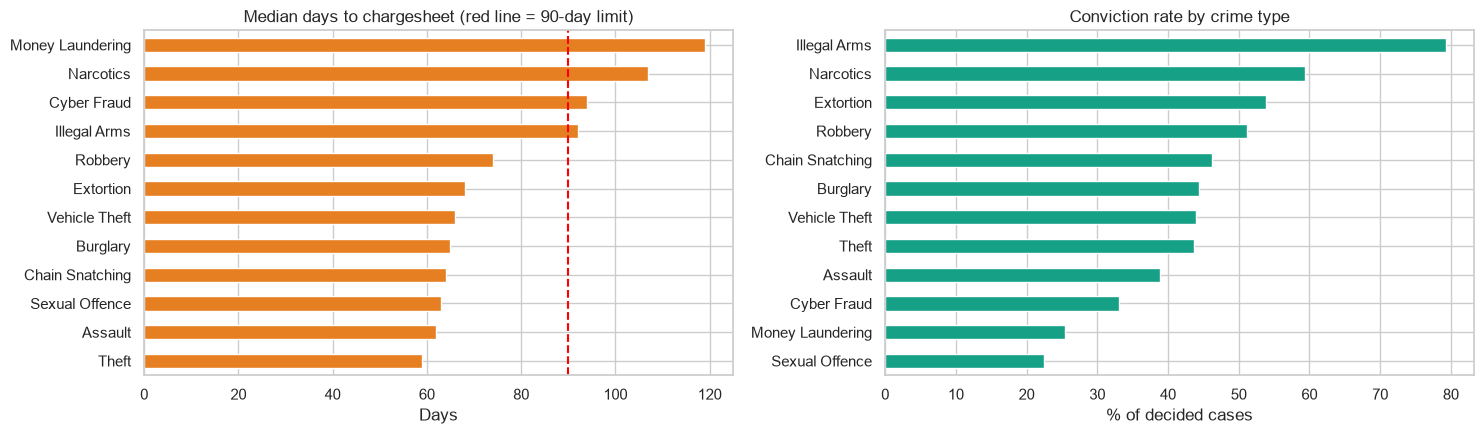

In [32]:
overdue = cp.overdue_chargesheets(cases)
pend_station = cp.pendency_by_station(cases)
delay_by_crime = cp.chargesheet_delay_by_crime(cases)
conviction = cp.conviction_rates(cases)
io_load = cp.io_workload(cases)
print(f"As of {AS_OF_DATE}: {int((cases['case_status'] == 'Under Investigation').sum())} pending investigations, "
      f"{len(overdue)} pending beyond 90 days")
display(overdue.head(10)); display(pend_station); display(delay_by_crime)
print(f"Overall conviction rate: {conviction.attrs['overall_rate']}%"); display(conviction)
display(io_load.head(8))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
delay_by_crime.set_index("crime_type")["median_days"].sort_values().plot.barh(ax=axes[0], color="#e67e22")
axes[0].axvline(90, ls="--", c="red"); axes[0].set_title("Median days to chargesheet (red line = 90-day limit)")
axes[0].set_xlabel("Days"); axes[0].set_ylabel("")
conviction.set_index("crime_type")["conviction_rate_%"].sort_values().plot.barh(ax=axes[1], color="#16a085")
axes[1].set_title("Conviction rate by crime type"); axes[1].set_xlabel("% of decided cases"); axes[1].set_ylabel("")
savefig("14_delay_and_conviction")

### 9.2 Supervised model: will the chargesheet miss the 90-day deadline? (mid-term stage H)
* **Target:** 1 if the chargesheet was filed after 90 days or is still pending after 90 days; 0 if filed within 90 days.
* **Features:** only what is known when the FIR is registered (no outcome columns: that would be leakage).
* **Pipeline (fitted on the training split only):** group-wise median imputation -> median / mode imputation ->
  log1p + StandardScaler -> ordinal + one-hot encoding -> VarianceThreshold -> classifier.
* **Models compared (course methods):** logistic regression, decision tree tuned with **GridSearchCV**,
  **KNN with cross-validation** over k, and random forest. Selection uses 5-fold cross-validated F1 on the
  training split; the test split is used once at the end. F1 is used because the classes are imbalanced (about
  1 in 3 cases is delayed) and missing a delayed case matters more than overall accuracy.

Decision tree best params: {'clf__max_depth': 8, 'clf__min_samples_leaf': 40} CV F1: 0.571


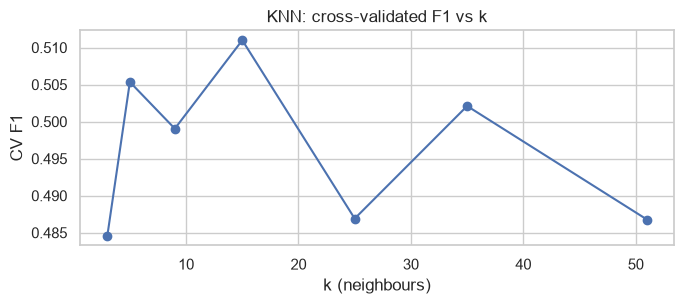

,model,best_params,cv_f1,accuracy,precision,recall,f1,roc_auc
0,Random forest,"{'clf__max_depth': 10, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 200}",0.6221,0.7009,0.5529,0.6438,0.5949,0.7638
1,Logistic regression,{'clf__C': 0.1},0.6178,0.7243,0.5769,0.7192,0.6402,0.7877
2,Decision tree,"{'clf__max_depth': 8, 'clf__min_samples_leaf': 40}",0.5708,0.6822,0.5248,0.7260,0.6092,0.7304
3,KNN,{'clf__n_neighbors': 15},0.5110,0.7313,0.6476,0.4658,0.5418,0.7373


Selected on CV F1: Random forest


In [33]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_tree = GridSearchCV(mp.build_pipeline("decision_tree"),
                         {"clf__max_depth": [3, 4, 5, 6, 8], "clf__min_samples_leaf": [5, 10, 20, 40]},
                         scoring="f1", cv=cv5, n_jobs=-1).fit(X_train, y_train)
print("Decision tree best params:", grid_tree.best_params_, "CV F1:", round(grid_tree.best_score_, 3))

grid_knn = GridSearchCV(mp.build_pipeline("knn"), {"clf__n_neighbors": [3, 5, 9, 15, 25, 35, 51]},
                        scoring="f1", cv=cv5, n_jobs=-1).fit(X_train, y_train)
knn_curve = pd.DataFrame(grid_knn.cv_results_)[["param_clf__n_neighbors", "mean_test_score"]]
plt.figure(figsize=(7, 3.2)); plt.plot(knn_curve.iloc[:, 0], knn_curve.iloc[:, 1], marker="o")
plt.title("KNN: cross-validated F1 vs k"); plt.xlabel("k (neighbours)"); plt.ylabel("CV F1"); savefig("15_knn_cv")

grid_lr = GridSearchCV(mp.build_pipeline("logreg"), {"clf__C": [0.01, 0.1, 1.0, 10.0]},
                       scoring="f1", cv=cv5, n_jobs=-1).fit(X_train, y_train)
grid_rf = GridSearchCV(mp.build_pipeline("random_forest"),
                       {"clf__n_estimators": [200], "clf__max_depth": [6, 10], "clf__min_samples_leaf": [3, 10]},
                       scoring="f1", cv=cv5, n_jobs=-1).fit(X_train, y_train)

results, fitted = [], {}
for name, g in [("Logistic regression", grid_lr), ("Decision tree", grid_tree), ("KNN", grid_knn), ("Random forest", grid_rf)]:
    fitted[name] = g.best_estimator_
    results.append({"model": name, "best_params": g.best_params_, "cv_f1": round(g.best_score_, 4),
                    **mp.evaluate(g.best_estimator_, X_test, y_test)})
comparison = pd.DataFrame(results).sort_values("cv_f1", ascending=False).reset_index(drop=True)
display(comparison)
best_name = comparison.iloc[0]["model"]; delay_model = fitted[best_name]
print(f"Selected on CV F1: {best_name}")

                precision    recall  f1-score   support

within 90 days       0.80      0.73      0.76       282
       delayed       0.55      0.64      0.59       146

      accuracy                           0.70       428
     macro avg       0.68      0.69      0.68       428
  weighted avg       0.71      0.70      0.71       428



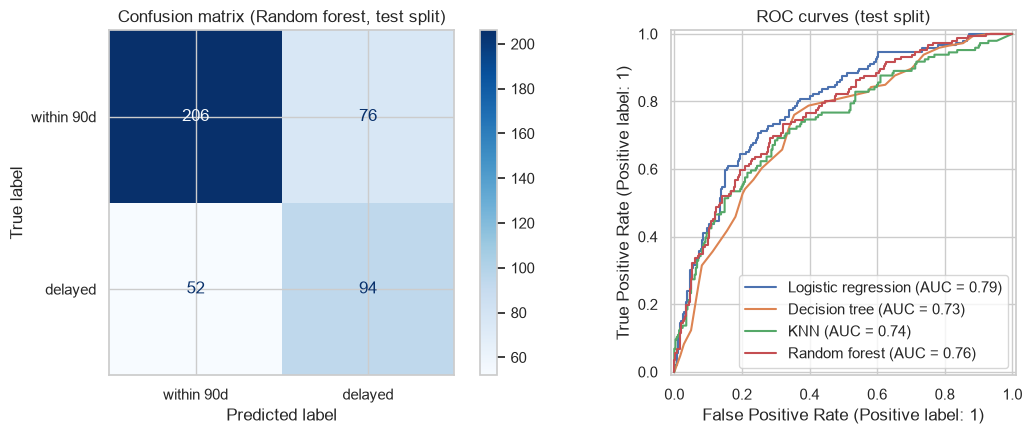

,feature,importance
0,io_caseload,0.0467
1,crime_type,0.0287
2,forensic_required,0.0140
3,police_station,0.0116
4,offence_gravity,0.0082
5,has_financial_trail,0.0081
6,has_cctv,0.0034
7,num_witnesses,0.0020
8,repeat_offender_involved,0.0011
9,num_accused,0.0001


In [34]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay, classification_report
print(classification_report(y_test, delay_model.predict(X_test), target_names=["within 90 days", "delayed"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_estimator(delay_model, X_test, y_test, display_labels=["within 90d", "delayed"], ax=axes[0], cmap="Blues")
axes[0].set_title(f"Confusion matrix ({best_name}, test split)")
for name, m in fitted.items():
    RocCurveDisplay.from_estimator(m, X_test, y_test, name=name, ax=axes[1])
axes[1].set_title("ROC curves (test split)"); savefig("16_confusion_roc")
perm = mp.raw_feature_importance(delay_model, X_test, y_test)
display(perm)

### 9.3 Early warning for cases that are still young
The model scores every case that is still under investigation and **younger than 90 days**, so supervisors can act
before the deadline is missed.

In [35]:
young = cases[(cases["case_status"] == "Under Investigation") & (cases["case_age_days"] <= 90)].copy()
young["delay_risk"] = delay_model.predict_proba(mp.to_model_frame(young))[:, 1].round(3)
risk_table = young.sort_values("delay_risk", ascending=False)[["fir_no", "police_station", "crime_type", "case_age_days", "io_id", "delay_risk"]]
display(risk_table.head(10))

,fir_no,police_station,crime_type,case_age_days,io_id,delay_risk
2248,VJN/0062/2026,Vijay Nagar,Money Laundering,84,VJN-IO1,0.889
2342,S12/0044/2026,Sector 12,Money Laundering,44,S12-IO2,0.875
2320,BHK/0098/2026,Bhawarkuan,Money Laundering,55,BHK-IO2,0.872
2264,BHK/0086/2026,Bhawarkuan,Narcotics,79,BHK-IO2,0.834
2263,BHK/0085/2026,Bhawarkuan,Cyber Fraud,79,BHK-IO2,0.829
2396,KRB/0039/2026,Karol Bagh,Cyber Fraud,30,KRB-IO4,0.808
2321,BHK/0099/2026,Bhawarkuan,Cyber Fraud,54,BHK-IO2,0.808
2243,KRB/0031/2026,Karol Bagh,Narcotics,86,KRB-IO1,0.806
2298,BHK/0092/2026,Bhawarkuan,Cyber Fraud,66,BHK-IO1,0.798
2367,DWN/0066/2026,Dewas Naka,Money Laundering,35,DWN-IO3,0.796


## 10. Insights and suggested next steps
Every analysis feeds rules that write **Insight -> Evidence (FIR numbers / data) -> Suggested next step -> Priority**.
Priority comes from a 0-1 score: Critical >= 0.85, High >= 0.65, Medium >= 0.40, otherwise Low.

In [36]:
book = ir.InsightBook(label=lambda n: label_map.get(n, label(n)))
ir.add_case_progress_insights(book, overdue, pend_station, conviction, io_load, risk_table)
ir.add_mo_insights(book, series, eval_series)
ir.add_network_insights(book, centrality, hidden, cycles,
                        bursts.assign(caller=bursts["caller"].map(lambda n: registry.resolve(n) or n)))
ir.add_hotspot_insights(book, hotspots, hot_inc)
ir.add_forecast_insights(book, forecast)
ir.add_trend_insights(book, cases, area_trends, city_trends, peaks)
ir.add_repeat_offender_insights(book, repeat)
insights = book.to_frame()
print(insights["priority"].value_counts().reindex(ir.PRIORITY_ORDER).to_string())

def show_insights(df):
    colour = {p: f"background-color: {c}; color: white; font-weight: 600" for p, c in ir.PRIORITY_COLOUR.items()}
    return (df[["insight_id", "priority", "category", "insight", "evidence", "suggested_next_step"]].style
              .map(lambda v: colour.get(v, ""), subset=["priority"])
              .set_properties(**{"text-align": "left", "white-space": "pre-wrap"}).hide(axis="index"))
show_insights(insights)

priority
Critical     5
High        23
Medium      13
Low          2


insight_id,priority,category,insight,evidence,suggested_next_step
INS-001,Critical,Case progress,66 investigations are pending beyond 90 days without a chargesheet (20 beyond 180 days).,"Oldest: BHK/0095/2025, BHK/0100/2025, S12/0070/2025, PLS/0118/2025, DWN/0111/2025, RAU/0074/2025 (+60 more)","Prioritise chargesheets pending over 90 days: weekly review by SHO/ACP, starting with the oldest."
INS-002,Critical,Pattern (MO),5 Extortion FIRs across 3 station(s) share the same modus operandi (2026-05-02 to 2026-05-11).,"FIRs: RJW/0047/2026, BHK/0054/2026, BHK/0057/2026, BHK/0056/2026, S12/0021/2026. MO: ""Shopkeeper near Bhawarkuan threatened by men in vehicle MP09AB1234; they demanded weekly protection money and warned of consequences. Complainant lives in ward "". Matched pairs naming a common accused: 80% (random pairs: 1%).","Link FIR RJW/0047/2026 and FIR BHK/0054/2026 (and the rest of the series) for joint investigation by Bhawarkuan, Rajwada, Sector 12; compare suspects, vehicles and CCTV."
INS-003,Critical,Pattern (MO),5 Extortion FIRs across 2 station(s) share the same modus operandi (2026-04-28 to 2026-06-01).,"FIRs: BHK/0053/2026, RJW/0052/2026, RJW/0056/2026, RJW/0061/2026, RJW/0062/2026. MO: ""Protection money demanded from shop owner near Bhawarkuan by two men arriving in vehicle MP09AB1234; repeated threatening calls received. No CCTV camera was fou"". Matched pairs naming a common accused: 80% (random pairs: 1%).","Link FIR BHK/0053/2026 and FIR RJW/0052/2026 (and the rest of the series) for joint investigation by Bhawarkuan, Rajwada; compare suspects, vehicles and CCTV."
INS-004,Critical,Network,Money moved in a closed loop: P-75646758 -> Chatterjee Traders -> P-3ce0003a -> P-75646758 (92.0% of the amount came back).,"Accounts ACC1002 -> ACC1004 -> ACC1001 -> ACC1002; amounts 480,000, 460,000, 500,000; 2026-08-05T10:00:00 to 2026-08-07T09:15:00.",Refer the accounts for financial-intelligence analysis and request bank statements; consider a freeze request under the applicable law.
INS-005,Critical,Hotspot,"Hotspot near Rajwada (H0): 154 FIRs within ~0.44 km, 17 in the last 90 days; mostly Theft.","Centre 22.7131, 75.8604; density 253.2/km2. FIRs: RJW/0099/2026, RJW/0097/2026, RJW/0093/2026, RJW/0092/2026 (+150 more)",Station a PCR van / picket at this spot during Afternoon (12-18); add CCTV coverage and street lighting check.
INS-006,High,Pattern (MO),8 Narcotics FIRs across 2 station(s) share the same modus operandi (2024-08-26 to 2024-10-26).,"FIRs: DWN/0059/2024, KRB/0035/2024, KRB/0036/2024, DWN/0070/2024, KRB/0043/2024 (+3 more). MO: ""Highway dhaba par Delhi number ki gaadi DL1CAB1234 se maal ka packet diya gaya. Padosiyon se poochtaach ki gayi."". Matched pairs naming a common accused: 80% (random pairs: 1%).","Link FIR DWN/0059/2024 and FIR KRB/0035/2024 (and the rest of the series) for joint investigation by Dewas Naka, Karol Bagh; compare suspects, vehicles and CCTV."
INS-007,High,Repeat offender,"P-36508347 is named in 61 FIRs across 9 station(s) and 2 district(s) (Extortion, Narcotics, Assault).","Latest FIRs: BHK/0057/2026, S12/0021/2026, RJW/0052/2026, S12/0023/2026, RJW/0061/2026, RJW/0062/2026, VJN/0055/2026, VJN/0058/2026. Pending: 1. Prior record: FIR 45/2023 - Extortion (co-accused).",Consolidate these cases with one supervising officer; update the history sheet from these records (documented cases only). Share with the other station(s)/district.
INS-008,High,Repeat offender,"P-3ce0003a is named in 51 FIRs across 8 station(s) and 2 district(s) (Extortion, Money Laundering, Assault).","Latest FIRs: BHK/0057/2026, RJW/0050/2026, S12/0021/2026, S12/0023/2026, RJW/0056/2026, RJW/0061/2026, S12/0031/2026, RJW/0092/2026. Pending: 1. Prior record: FIR 45/2023 - Extortion; FIR 12/2021 - Assault.",Consolidate these cases with one supervising officer; update the history sheet from these records (documented cases only). Share with the other station(s)/district.
INS-009,High,Repeat offender,"P-fa16c517 is na

### 10.1 Taking in new FIRs automatically
New FIRs go through the same cleaning rules, then are scored by the trained delay model, matched against past MOs,
checked for accused already on record and placed against the known hotspots. Three example FIRs are shown below
(one in Hinglish).

In [37]:
new_raw = pd.DataFrame([
    {"fir_no": "BHK/0901/2026", "police_station": "BHAWARKUAN P.S.", "district": "Indore", "date_occurred": "2026-09-20",
     "date_registered": "2026-09-21", "hour_of_occurrence": 11, "crime_type": "Extortion", "ipc_sections": "IPC 384; IPC 506",
     "modus_operandi": "Shopkeeper near Bhawarkuan threatened by men in vehicle MP09AB1234; they demanded weekly protection money and warned of consequences.",
     "latitude": 22.7025, "longitude": 75.8600, "accused_names": "Vikram Rathore; Zubair Khan", "num_accused": 2, "num_witnesses": 1,
     "complainant_name": "Test Complainant", "complainant_phone": "9000000001", "complainant_address": "1, Ward 2, Bhawarkuan, Indore",
     "victim_name": "", "property_value_inr": 50000, "io_id": "BHK-IO2", "io_caseload": 44, "registration_delay_days": 1,
     "has_cctv": "No", "has_cdr_evidence": "Yes", "has_financial_trail": "Yes", "forensic_required": "No",
     "case_status": "Under Investigation", "chargesheet_date": None, "court_status": "", "property_value_lakh": 0.5},
    {"fir_no": "RJW/0902/2026", "police_station": "Rajwada", "district": "Indore", "date_occurred": "2026-09-22",
     "date_registered": "22/09/2026", "hour_of_occurrence": 19, "crime_type": "Chain Snatching", "ipc_sections": "IPC 356; IPC 379",
     "modus_operandi": "Kaali bike par bina number plate ke do ladke aaye aur shaam ko Rajwada ke paas mahila ki chain chheen li.",
     "latitude": 22.7240, "longitude": 75.8520, "accused_names": "Unknown", "num_accused": 0, "num_witnesses": 2,
     "complainant_name": "Test Complainant 2", "complainant_phone": "9000000002", "complainant_address": "5, Ward 9, Rajwada, Indore",
     "victim_name": "", "property_value_inr": 90000, "io_id": "RJW-IO1", "io_caseload": 20, "registration_delay_days": 0,
     "has_cctv": "Yes", "has_cdr_evidence": "No", "has_financial_trail": "No", "forensic_required": "No",
     "case_status": "Under Investigation", "chargesheet_date": None, "court_status": "", "property_value_lakh": 0.9},
    {"fir_no": "VJN/0903/2026", "police_station": "Vijaynagar", "district": "Indore", "date_occurred": "2026-09-23",
     "date_registered": "2026-09-25", "hour_of_occurrence": 14, "crime_type": "Cyber Fraud", "ipc_sections": "IPC 420; IT Act 66D",
     "modus_operandi": "Complainant received a phone call from a person posing as bank officer, shared OTP and lost Rs 1.2 lakh.",
     "latitude": 22.7525, "longitude": 75.8980, "accused_names": "Unknown", "num_accused": 0, "num_witnesses": 0,
     "complainant_name": "Test Complainant 3", "complainant_phone": "9000000003", "complainant_address": "9, Ward 40, Vijay Nagar, Indore",
     "victim_name": "", "property_value_inr": 120000, "io_id": "VJN-IO3", "io_caseload": 52, "registration_delay_days": 2,
     "has_cctv": "No", "has_cdr_evidence": "Yes", "has_financial_trail": "Yes", "forensic_required": "No",
     "case_status": "Under Investigation", "chargesheet_date": None, "court_status": "", "property_value_lakh": 1.2},
])
new_firs = nf.prepare_new_firs(new_raw, cases)
new_insights = nf.analyse_new_firs(new_firs, cases, matcher, delay_model, hotspots, label=label)
show_insights(new_insights)

insight_id,priority,category,insight,evidence,suggested_next_step
INS-001,Critical,New FIR: pattern (MO),"BHK/0901/2026 matches the modus operandi of 3 FIR(s) from the last 365 days, including the same vehicle/phone MP09AB1234.",BHK/0056/2026 (similarity 0.93); BHK/0057/2026 (similarity 0.93); BHK/0054/2026 (similarity 0.87),"Link FIR BHK/0901/2026 and FIR BHK/0056/2026 for joint investigation; compare suspects, vehicles and CCTV."
INS-002,High,New FIR: repeat offender,Accused P-3ce0003a in BHK/0901/2026 is already named in 51 earlier FIR(s).,"S12/0023/2026, RJW/0056/2026, RJW/0061/2026, S12/0031/2026, RJW/0092/2026",Attach the earlier case records to this investigation (documented cases only).
INS-003,High,New FIR: repeat offender,Accused P-fa16c517 in BHK/0901/2026 is already named in 36 earlier FIR(s).,"RJW/0052/2026, S12/0023/2026, RJW/0056/2026, RJW/0061/2026, RJW/0062/2026",Attach the earlier case records to this investigation (documented cases only).
INS-004,High,New FIR: case progress,"VJN/0903/2026 (Cyber Fraud, Vijay Nagar): 73% risk of missing the 90-day chargesheet deadline.","Accused 0, IO caseload 52, forensic no, financial trail yes.",Assign a supervising officer and set interim deadlines.
INS-005,High,New FIR: case progress,"BHK/0901/2026 (Extortion, Bhawarkuan): 65% risk of missing the 90-day chargesheet deadline.","Accused 2, IO caseload 44, forensic no, financial trail yes.",Assign a supervising officer and set interim deadlines.
INS-006,Medium,New FIR: pattern (MO),VJN/0903/2026 matches the modus operandi of 2 FIR(s) from the last 365 days.,RAU/0035/2026 (similarity 0.87); S12/0007/2026 (similarity 0.83),"Link FIR VJN/0903/2026 and FIR RAU/0035/2026 for joint investigation; compare suspects, vehicles and CCTV."
INS-007,Medium,New FIR: hotspot,BHK/0901/2026 occurred inside hotspot H1 near Bhawarkuan.,"128 earlier FIRs in this hotspot, mostly Theft.",Add this location to the Evening (18-24) patrol route.
INS-008,Medium,New FIR: hotspot,RJW/0902/2026 occurred inside hotspot H7 near Rajwada.,"132 earlier FIRs in this hotspot, mostly Theft.",Add this location to the Evening (18-24) patrol route.
INS-009,Medium,New FIR: case progress,"RJW/0902/2026 (Chain Snatching, Rajwada): 14% risk of missing the 90-day chargesheet deadline.","Accused 0, IO caseload 20, forensic no, financial trail no.",Routine monitoring.


## 11. Save trained models and export the report
* `models/`: notebook artefacts (delay model chosen here, MO matcher, forecasts, restricted identity table), git-ignored;
* `model/model.joblib` (served by the API) is produced by `train.py`, which uses the same pipeline and logs every
  run to MLflow. Set `UPDATE_SERVED_MODEL = True` to replace it with the model chosen in this notebook;
* `reports/`: insight report (CSV + HTML), dashboard (HTML), hotspot map, network graph, figures.

In [38]:
import joblib
UPDATE_SERVED_MODEL = False
(ROOT / "models").mkdir(exist_ok=True)
joblib.dump(delay_model, ROOT / "models" / "delay_model.joblib")
best_row = comparison.iloc[0]
algo = {"Logistic regression": "logreg", "Decision tree": "decision_tree", "KNN": "knn", "Random forest": "random_forest"}[best_name]
meta = {"params": {"algorithm": algo, **{k.replace("clf__", ""): v for k, v in best_row["best_params"].items()}},
        "metrics": {k: float(best_row[k]) for k in ["accuracy", "precision", "recall", "f1", "roc_auc"]} | {"cv_f1_mean": float(best_row["cv_f1"])},
        "features": MODEL_FEATURES, "target": TARGET, "trained_at": pd.Timestamp.now().isoformat(timespec="seconds"),
        "feature_importance": perm.head(8).to_dict(orient="records"), "training_stats": mp.training_stats(X_train)}
(ROOT / "models" / "delay_model_metadata.json").write_text(json.dumps(meta, indent=2, default=str))
if UPDATE_SERVED_MODEL:
    joblib.dump(delay_model, ROOT / "model" / "model.joblib")
    (ROOT / "model" / "metadata.json").write_text(json.dumps(meta, indent=2, default=str))
    print("Replaced model/model.joblib with", best_name)
matcher._encoder = None   # do not pickle the downloaded transformer weights
joblib.dump(matcher, ROOT / "models" / "mo_matcher.joblib")
forecast.to_csv(ROOT / "models" / "station_forecast.csv", index=False)

insights.to_csv(REPORT_DIR / "insights_report.csv", index=False)
(REPORT_DIR / "insights_report.html").write_text(ir.to_html_report(insights), encoding="utf-8")
new_insights.to_csv(REPORT_DIR / "new_fir_insights.csv", index=False)
series.to_csv(REPORT_DIR / "mo_series.csv", index=False)
overdue.to_csv(REPORT_DIR / "overdue_chargesheets.csv", index=False)
print("Saved models:", *sorted(p.name for p in (ROOT / "models").iterdir() if p.is_file()), sep="\n  ")
print("Saved reports:", *sorted(p.name for p in REPORT_DIR.iterdir() if p.is_file()), sep="\n  ")

Saved models:
  .gitkeep
  delay_model.joblib
  delay_model_metadata.json
  mo_matcher.joblib
  station_forecast.csv
Saved reports:
  dashboard.html
  hotspot_map.html
  insights_report.csv
  insights_report.html
  mo_series.csv
  network.html
  new_fir_insights.csv
  overdue_chargesheets.csv


### 11.1 Dashboard
One HTML page with priority counts, the top insights, the hotspot map and interactive charts
(`reports/dashboard.html`). Open it in a browser, or download it from Colab's file panel.

In [39]:
import plotly.express as px
mc = tr.monthly_counts(cases, by="crime_type").reset_index().melt(id_vars="month_start", var_name="crime_type", value_name="firs")
figs = {
    "Monthly FIRs by crime type": px.line(mc, x="month_start", y="firs", color="crime_type", labels={"month_start": "Month", "firs": "FIRs"}),
    "4-week forecast by police station": px.bar(forecast, x="police_station", y="forecast_next_weeks", color="best_model",
                                                labels={"forecast_next_weeks": "Forecast FIRs (next 4 weeks)", "police_station": "Police station"}),
    "Pending and overdue investigations": px.bar(pend_station, x="police_station", y=["pending", "overdue_90d"], barmode="group",
                                                 labels={"value": "Cases", "police_station": "Police station", "variable": ""}),
    "Conviction rate by crime type": px.bar(conviction, x="conviction_rate_%", y="crime_type", orientation="h",
                                            labels={"conviction_rate_%": "Conviction rate (%)", "crime_type": ""}),
    "Criminal network": fig_net,
}
(REPORT_DIR / "dashboard.html").write_text(ir.build_dashboard(figs, insights, map_file="hotspot_map.html"), encoding="utf-8")
print("Saved reports/dashboard.html")
display(HTML(f"<b>Priority summary:</b> " + " | ".join(f"{p}: {n}" for p, n in insights['priority'].value_counts().reindex(ir.PRIORITY_ORDER, fill_value=0).items())))

Saved reports/dashboard.html


## 12. Deployment (how the trained model is served)
The notebook is for analysis; the repository turns the delay model into a production-style service, as the
CSL236 end-term guidelines require:

| Stage | File | What it does |
|---|---|---|
| Training + tracking | `train.py` | trains with CLI hyperparameters, logs runs to MLflow (`sqlite:///mlflow.db`), saves the best model |
| API + UI | `app.py`, `static/index.html` | FastAPI: `GET /health`, `POST /predict` (Pydantic contract, 422 on bad input), UI at `/` with tips |
| Tests | `tests/` | health, UI, domain logic, 422 boundaries, cleaning, anonymisation, Hindi normalisation |
| Container | `Dockerfile`, `requirements-serve.txt` | `python:3.11-slim`, serve-only dependencies |
| CI | `.github/workflows/ci.yml` | on every push to `main`: install, check the data generator, train, pytest, build and smoke-test the image |
| Monitoring | `logs/predictions.jsonl`, `scripts/drift_check.py` | every prediction input is logged; the drift check compares it with training statistics |

```bash
python train.py --sweep                          # 6 runs, 4 algorithms -> model/model.joblib
mlflow ui --backend-store-uri sqlite:///mlflow.db
uvicorn app:app --reload --port 8000             # http://localhost:8000 and /docs
pytest -v --tb=short
docker build -t fir-crime-insights . && docker run -d -p 8000:8000 --restart unless-stopped fir-crime-insights
```

## 13. Limitations, ethics and references
**Limitations.** The case register is synthetic, so the model has learned the generator's rules; the numbers show
that the pipeline works, not how real police data behaves. Real deployment needs real, access-controlled data,
re-validation, and review of every suggested action by an officer.

**Ethics and privacy.** Pseudonymised identities; masked phones and addresses; victim identity in sexual-offence cases
never shown; no caste, religion or community features (`drop_protected_attributes` removes them if present);
person-level insights only from documented FIRs; real FIR data is never committed (`.gitignore`); with real data,
keep the identity lookup and salt in restricted, logged storage and follow the applicable data-protection and police
data-handling rules.

**References (external sources used).**
1. scikit-learn user guide: pipelines, ColumnTransformer, GridSearchCV, KMeans, DBSCAN, permutation importance (scikit-learn.org), used for the modelling code.
2. statsmodels documentation: Holt-Winters ExponentialSmoothing (statsmodels.org), used for forecasting.
3. NetworkX documentation: centrality, communities, Adamic-Adar, simple cycles (networkx.org), used for link analysis.
4. Reimers & Gurevych (2020), *Making Monolingual Sentence Embeddings Multilingual using Knowledge Distillation* - the multilingual MiniLM model used for optional MO embeddings.
5. Bharatiya Nyaya Sanhita, 2023 and the MHA IPC-BNS correspondence, used for the IPC-to-BNS mapping (verify before real use).
6. CSL236 Mid-Term and End-Term Project Guidelines (The NorthCap University), used for the project structure.
7. AI coding assistant (Claude) used to help draft code and documentation; every part was reviewed and can be explained by the team.